# Análisis de la curva de rendimientos nominal mexicana

## Introducción

Este notebook documenta el análisis desarrollado para el ejercicio de Junior Statistician de Tukan sobre la curva de rendimientos nominal mexicana. El objetivo es responder, en orden, tres preguntas: si existe una estructura común en cómo se mueven los nueve plazos de la curva, si esa curva se puede pronosticar a uno y a cuatro trimestres, y si la estructura identificada en la primera pregunta ayuda a mejorar los pronósticos de la segunda.

**Base de datos utilizada:** `banxico_auction_rates_monthly.csv`, con observaciones mensuales de la tasa promedio pagada en subasta para nueve instrumentos (CETEs a cuatro plazos, MBONOs a cinco), de octubre de 2006 a septiembre de 2026. Fuente: Banco de México, vía el data warehouse de Tukan.

**Preguntas a responder:**
1. ¿Existe estructura en cómo se mueven en conjunto los nueve plazos?
2. ¿Podemos pronosticar la curva, a un trimestre y a cuatro trimestres adelante?
3. ¿La estructura de la pregunta 1, si existe, mejora los pronósticos de la pregunta 2?

**Enfoque metodológico propuesto:** la estructura conjunta de los nueve plazos se explora mediante análisis de componentes principales (PCA), identificando factores comunes de nivel, pendiente y curvatura. La pronosticabilidad de la curva se evalúa comparando un benchmark naive (persistencia o random walk) contra un modelo multivariado (VAR(1) sobre los nueve plazos). Finalmente, se evalúa si modelar la curva a través de sus factores principales (PCA + VAR(1)) mejora el pronóstico frente a ambas alternativas anteriores, usando los mismos orígenes y horizontes de prueba en todos los casos.

**Índice:**
- Módulo 1 — Auditoría, entendimiento del problema y alcance
- Módulo 2 — Preparación de datos
- Módulo 3 — Estructura de la curva mediante PCA
- Módulo 4 — Pronóstico con benchmark
- Módulo 5 — Pronóstico multivariado con VAR(1)
- Módulo 6 — Pregunta 3: pronóstico estructural con PCA + VAR(1)
- Resumen ejecutivo

Las decisiones metodológicas relevantes se reportan a lo largo del notebook, en las secciones de "Observaciones" y "Comentarios" de cada paso. Para mayor detalle sobre decisiones, alternativas descartadas y cosas que no funcionaron, se elaboró una bitácora aparte, como lo pide el ejercicio.

Al final de este notebook se incluye un resumen ejecutivo que condensa los hallazgos de las tres preguntas. Este resumen es un documento adicional de apoyo — el brief (PDF, máximo 5 páginas) y la presentación son los entregables formales del ejercicio.

## Módulo 1 — Auditoría y alcance

Primero se revisan las fuentes, la estructura de los datos y las decisiones metodológicas que delimitan el análisis. Después, el notebook avanza de forma secuencial: prepara la base, identifica los factores comunes de la curva y evalúa distintos modelos de pronóstico.



### Paso 1 — Importar librerias, ubicar y verificar las fuentes

Se importan librerías y se identifican las rutas de los archivos que alimentan el análisis: la base mensual de subastas. Para este caso, se propuso además traer la tasa objetivo de Banxico como recurso de apoyo durante la exploración de los datos. Antes de leer los datos se comprueba que ambos archivos existan en el proyecto; así se evita continuar con rutas incorrectas o con una fuente ausente.


In [38]:
from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Ruta relativa: funciona lanzando el notebook desde la raíz del repo o desde notebooks/
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
CSV_PATH = PROJECT_DIR / 'data' / 'raw' / 'banxico_auction_rates_monthly.csv'
BANXICO_PATH = PROJECT_DIR / 'data' / 'raw' / 'tasa_banxico.xlsx'

print('Directorio del proyecto:', PROJECT_DIR)
print('CSV existe:', CSV_PATH.exists())
print('Base Banxico existe:', BANXICO_PATH.exists())

Directorio del proyecto: C:\Users\Max Santana\Documents\Python\Proyectos con Python\Curvas de rendimiento - Banxico
CSV existe: True
Base Banxico existe: True


### Paso 2 — Auditar cobertura, estructura y calidad

Se carga la base cruda y se revisan sus dimensiones principales: número de filas y columnas, fechas distintas, instrumentos disponibles, duplicados por fecha e instrumento, valores faltantes e indicador utilizado. También se observa la cobertura por instrumento para detectar diferencias de longitud entre plazos.

Esta auditoría establece el punto de partida del análisis y permite distinguir faltantes esperables del calendario de subastas de posibles problemas de calidad.


In [39]:
crudo = pd.read_csv(CSV_PATH, parse_dates=['DATE'])

resumen = pd.DataFrame({
    'filas': [len(crudo)],
    'columnas': [crudo.shape[1]],
    'fechas_distintas': [crudo['DATE'].nunique()],
    'instrumentos_distintos': [crudo['INSTRUMENT'].nunique()],
    'duplicados_fecha_instrumento': [crudo.duplicated(['DATE', 'INSTRUMENT']).sum()],
    'faltantes_valor': [crudo['VALUE_PCT'].isna().sum()],
})
display(resumen)
print('Rango:', crudo['DATE'].min().date(), 'a', crudo['DATE'].max().date())
print('Indicadores:', crudo['INDICATOR'].unique().tolist())
display(crudo.groupby('INSTRUMENT').size().rename('observaciones').to_frame())

,filas,columnas,fechas_distintas,instrumentos_distintos,duplicados_fecha_instrumento,faltantes_valor
0,1936,4,240,9,0,0


Rango: 2006-10-01 a 2026-09-01
Indicadores: ['Annualized monthly average rate']


,observaciones
INSTRUMENT,
"CETEs, 182 days",240
"CETEs, 28 days",240
"CETEs, 364 days",240
"CETEs, 91 days",240
"MBONOs, 10 years",177
"MBONOs, 20 years",171
"MBONOs, 3 years",236
"MBONOs, 30 years",168
"MBONOs, 5 years",224


### Cierre del Módulo 1 — Resultado de la auditoría

La revisión en Python y la inspección manual de los archivos confirman lo siguiente:

- 1,936 registros.
- Periodo de octubre de 2006 a septiembre de 2026.
- Nueve instrumentos, con plazos cortos y largos.
- Cero registros duplicados.
- El indicador corresponde al promedio de tasas porcentuales anualizadas.
- Existen NAs mensuales en plazos largos, los cuales son normales y responden al calendario de subastas.

La base es adecuada para continuar. Los siguientes pasos son 1) transformar los registros largos en una matriz mensual más legible donde cada fila sea una fecha y cada columna un plazo, y 2) decidir qué hacer con los NAs


## Módulo 2 — Preparación y exploración de los datos

Se reorganizan los registros en una tabla mensual por plazo, se revisan los faltantes y se preparan ejemplos visuales de la forma de la curva con los datos actuales. Esta base será la entrada de los modelos PCA y de pronóstico.

### Paso 1 — Preparar la matriz mensual por plazo

Se fija el orden económico de los nueve plazos, se renombran con etiquetas cortas y se transforma la base de formato largo a formato ancho mediante un *pivot*. Después se construye el calendario mensual completo y se cuantifican los faltantes por plazo.


In [40]:
orden = [
    'CETEs, 28 days', 'CETEs, 91 days', 'CETEs, 182 days', 'CETEs, 364 days',
    'MBONOs, 3 years', 'MBONOs, 5 years', 'MBONOs, 10 years',
    'MBONOs, 20 years', 'MBONOs, 30 years'
]
#Renombrar a nombres cortos más ágiles para posterior análisis
nombres_cortos = ['28d', '91d', '182d', '364d', '3a', '5a', '10a', '20a', '30a']
#Transformación de formato de fechas correcto 
meses = pd.date_range('2006-10-01', '2026-09-01', freq='MS')
#Transposición de datos de tal manera que ahora cada fila es un mes tasas_mensuales_por_plazo cada columna un plazo
tasas_mensuales_por_plazo = (crudo.pivot(index='DATE', columns='INSTRUMENT', values='VALUE_PCT')
       .reindex(index=meses, columns=orden))
print(tasas_mensuales_por_plazo.head(5))
tasas_mensuales_por_plazo.columns = nombres_cortos
tasas_mensuales_por_plazo.index.name = 'mes'

resumen_faltantes = pd.DataFrame({
    'observaciones': tasas_mensuales_por_plazo.notna().sum(),
    'faltantes': tasas_mensuales_por_plazo.isna().sum(),
    'porcentaje_faltante': (tasas_mensuales_por_plazo.isna().mean() * 100).round(1),
})
display(resumen_faltantes)

porcentaje_completo = tasas_mensuales_por_plazo.notna().all(axis=1).mean() * 100
porcentaje_global_NAs = tasas_mensuales_por_plazo.isna().mean().mean()*100


print("Porcentaje global de NAs en el dataset:",
      round(porcentaje_global_NAs,2),
      "%"
)

print(
    "Porcentaje de meses sin los nueve plazos completos:",
    round(100.0-porcentaje_completo, 2),
    "%"
)

print(
    "Porcentaje de meses con los nueve plazos completos:",
    round(porcentaje_completo, 2),
    "%"
)

print('Meses con los nueve plazos completos:', int(tasas_mensuales_por_plazo.notna().all(axis=1).sum()), 'de', len(tasas_mensuales_por_plazo))



INSTRUMENT  CETEs, 28 days  CETEs, 91 days  CETEs, 182 days  CETEs, 364 days  \
2006-10-01            7.05            7.21             7.42             7.50   
2006-11-01            7.04            7.16             7.26             7.28   
2006-12-01            7.04            7.16             7.20             7.27   
2007-01-01            7.04            7.19             7.31             7.46   
2007-02-01            7.04            7.19             7.34             7.38   

INSTRUMENT  MBONOs, 3 years  MBONOs, 5 years  MBONOs, 10 years  \
2006-10-01             7.62             7.88              8.40   
2006-11-01             7.39             7.50              7.88   
2006-12-01             7.18             7.28              7.56   
2007-01-01             7.70             7.52              7.43   
2007-02-01             7.47             7.70              7.96   

INSTRUMENT  MBONOs, 20 years  MBONOs, 30 years  
2006-10-01               NaN              8.08  
2006-11-01              

,observaciones,faltantes,porcentaje_faltante
28d,240,0,0.0
91d,240,0,0.0
182d,240,0,0.0
364d,240,0,0.0
3a,236,4,1.7
5a,224,16,6.7
10a,177,63,26.2
20a,171,69,28.7
30a,168,72,30.0


Porcentaje global de NAs en el dataset: 10.37 %
Porcentaje de meses sin los nueve plazos completos: 83.33 %
Porcentaje de meses con los nueve plazos completos: 16.67 %
Meses con los nueve plazos completos: 40 de 240


### Paso 2 — Visualizar cobertura y faltantes

Antes de decidir cómo tratar los faltantes, se grafican las nueve series con sus valores observados. La visualización permite verificar la cobertura temporal, identificar qué plazos tienen interrupciones y comprobar que los movimientos registrados son plausibles.

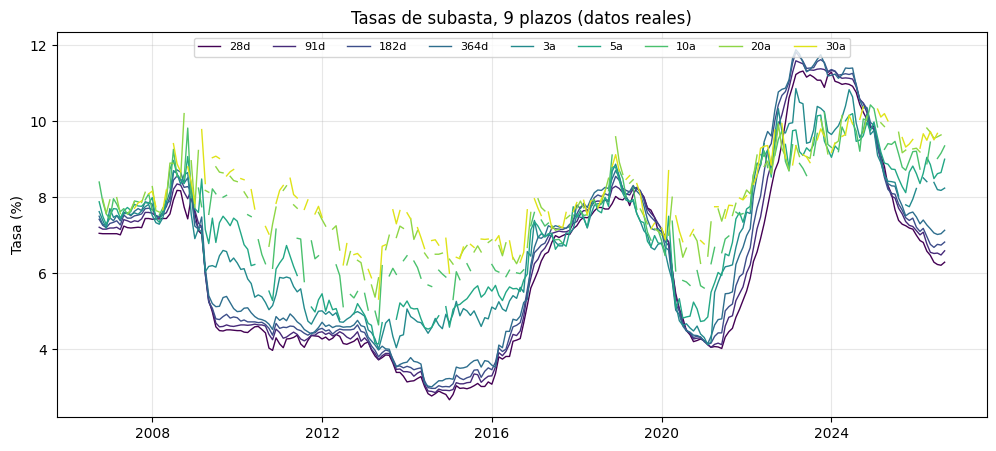

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))
colores = plt.cm.viridis(np.linspace(0, 0.95, 9))
# Usa la tabla ya preparada en el notebook y no dependas de variables inexistentes
for plazo, col in zip(tasas_mensuales_por_plazo.columns, colores):
    ax.plot(
        tasas_mensuales_por_plazo.index,
        tasas_mensuales_por_plazo[plazo],
        lw=1,
        color=col,
        label=plazo,
    )
ax.set_ylabel("Tasa (%)")
ax.set_title("Tasas de subasta, 9 plazos (datos reales)")
ax.legend(ncol=9, fontsize=8, loc="upper center")
ax.grid(alpha=0.3)
plt.show()


### Resultado del Paso 2 — Decisión sobre los faltantes

Aunque solo 40 de los 240 meses tienen los nueve plazos completos, no se eliminan los meses incompletos: conservar únicamente esas 40 observaciones implicaría perder una cantidad importante de información. La ausencia de algunos plazos es normal y responde al calendario de subastas y emisiones de Hacienda, especialmente en los instrumentos de mayor plazo.

Se aplica *forward-fill* porque es una alternativa simple, transparente y consistente con el alcance práctico del ejercicio. El procedimiento utiliza únicamente la última observación disponible en el pasado; no se aplica *backfill* ni información futura. El primer faltante del bono de 20 años se conserva como `NaN`: no se rellena artificialmente ni se elimina ese mes de la base original. Una alternativa más avanzada a *forward-fill* habría sido usar la función Nelson-Siegel usada en Diebold y Li (2006), la cual ajusta la curva a los ocho plazos observados en cada mes y usa esa curva para estimar el valor del plazo faltante, en vez de arrastrar el último valor observado en el pasado. Por restricción de tiempo, costo computacional y de programación se decidió no utilizarla en este proyecto, si bien es una mejor alternativa.

Esta decisión permite conservar la dimensión temporal necesaria para el análisis. A continuación se construyen curvas representativas para conectar la tabla de tasas con las formas económicas que se estudiarán mediante PCA.


### Paso 3 — Construir y comparar formas de la curva

Antes de avanzar de avanzar de lleno en la exploración de una estructura en los datos, se construyó una exploración de las formas clásicas de la curva de rendimientos con fines de comprensión propia. No es un requisito explícito del ejercicio, pero ayudó a interpretar con más criterio la selección de siguientes pasos.

Una curva de rendimientos es una **fotografía de un mes**: muestra cómo se distribuyen las tasas entre los nueve plazos, desde 28 días hasta 30 años. En la base, cada fila representa una curva observada en una fecha. Una serie temporal, en cambio, muestra cómo evoluciona un plazo específico a lo largo de los meses: cada columna representa un plazo y cada fila, una fecha. El siguiente bloque lee explícitamente la base procesada `tasas_mensuales_forward_fill.csv` y selecciona tipos de curva más habituales que se explican a continuación.

Bloque central seleccionado: 364d, 3a, 5a | pico: 364d | contraste: 0.75 puntos porcentuales
Fechas seleccionadas:

- Curva inclinada: 2009-09
- Curva invertida: 2023-07
- Curva plana: 2008-04
- Curva jorobada: 2022-07
- Último mes: 2026-09

Tasas por plazo:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
Tipo de curva,,,,,,,,,
Curva inclinada,4.48,4.60,4.86,5.36,6.60,7.50,8.00,8.64,9.02
Curva invertida,11.22,11.35,11.40,11.36,9.45,9.21,8.57,9.02,8.91
Curva plana,7.44,7.54,7.61,7.60,7.46,7.62,7.72,7.61,7.67
Curva jorobada,7.76,8.53,9.24,9.73,9.41,9.24,8.78,8.95,9.36
Último mes,6.29,6.59,6.82,7.13,8.24,9.00,9.35,9.64,9.87


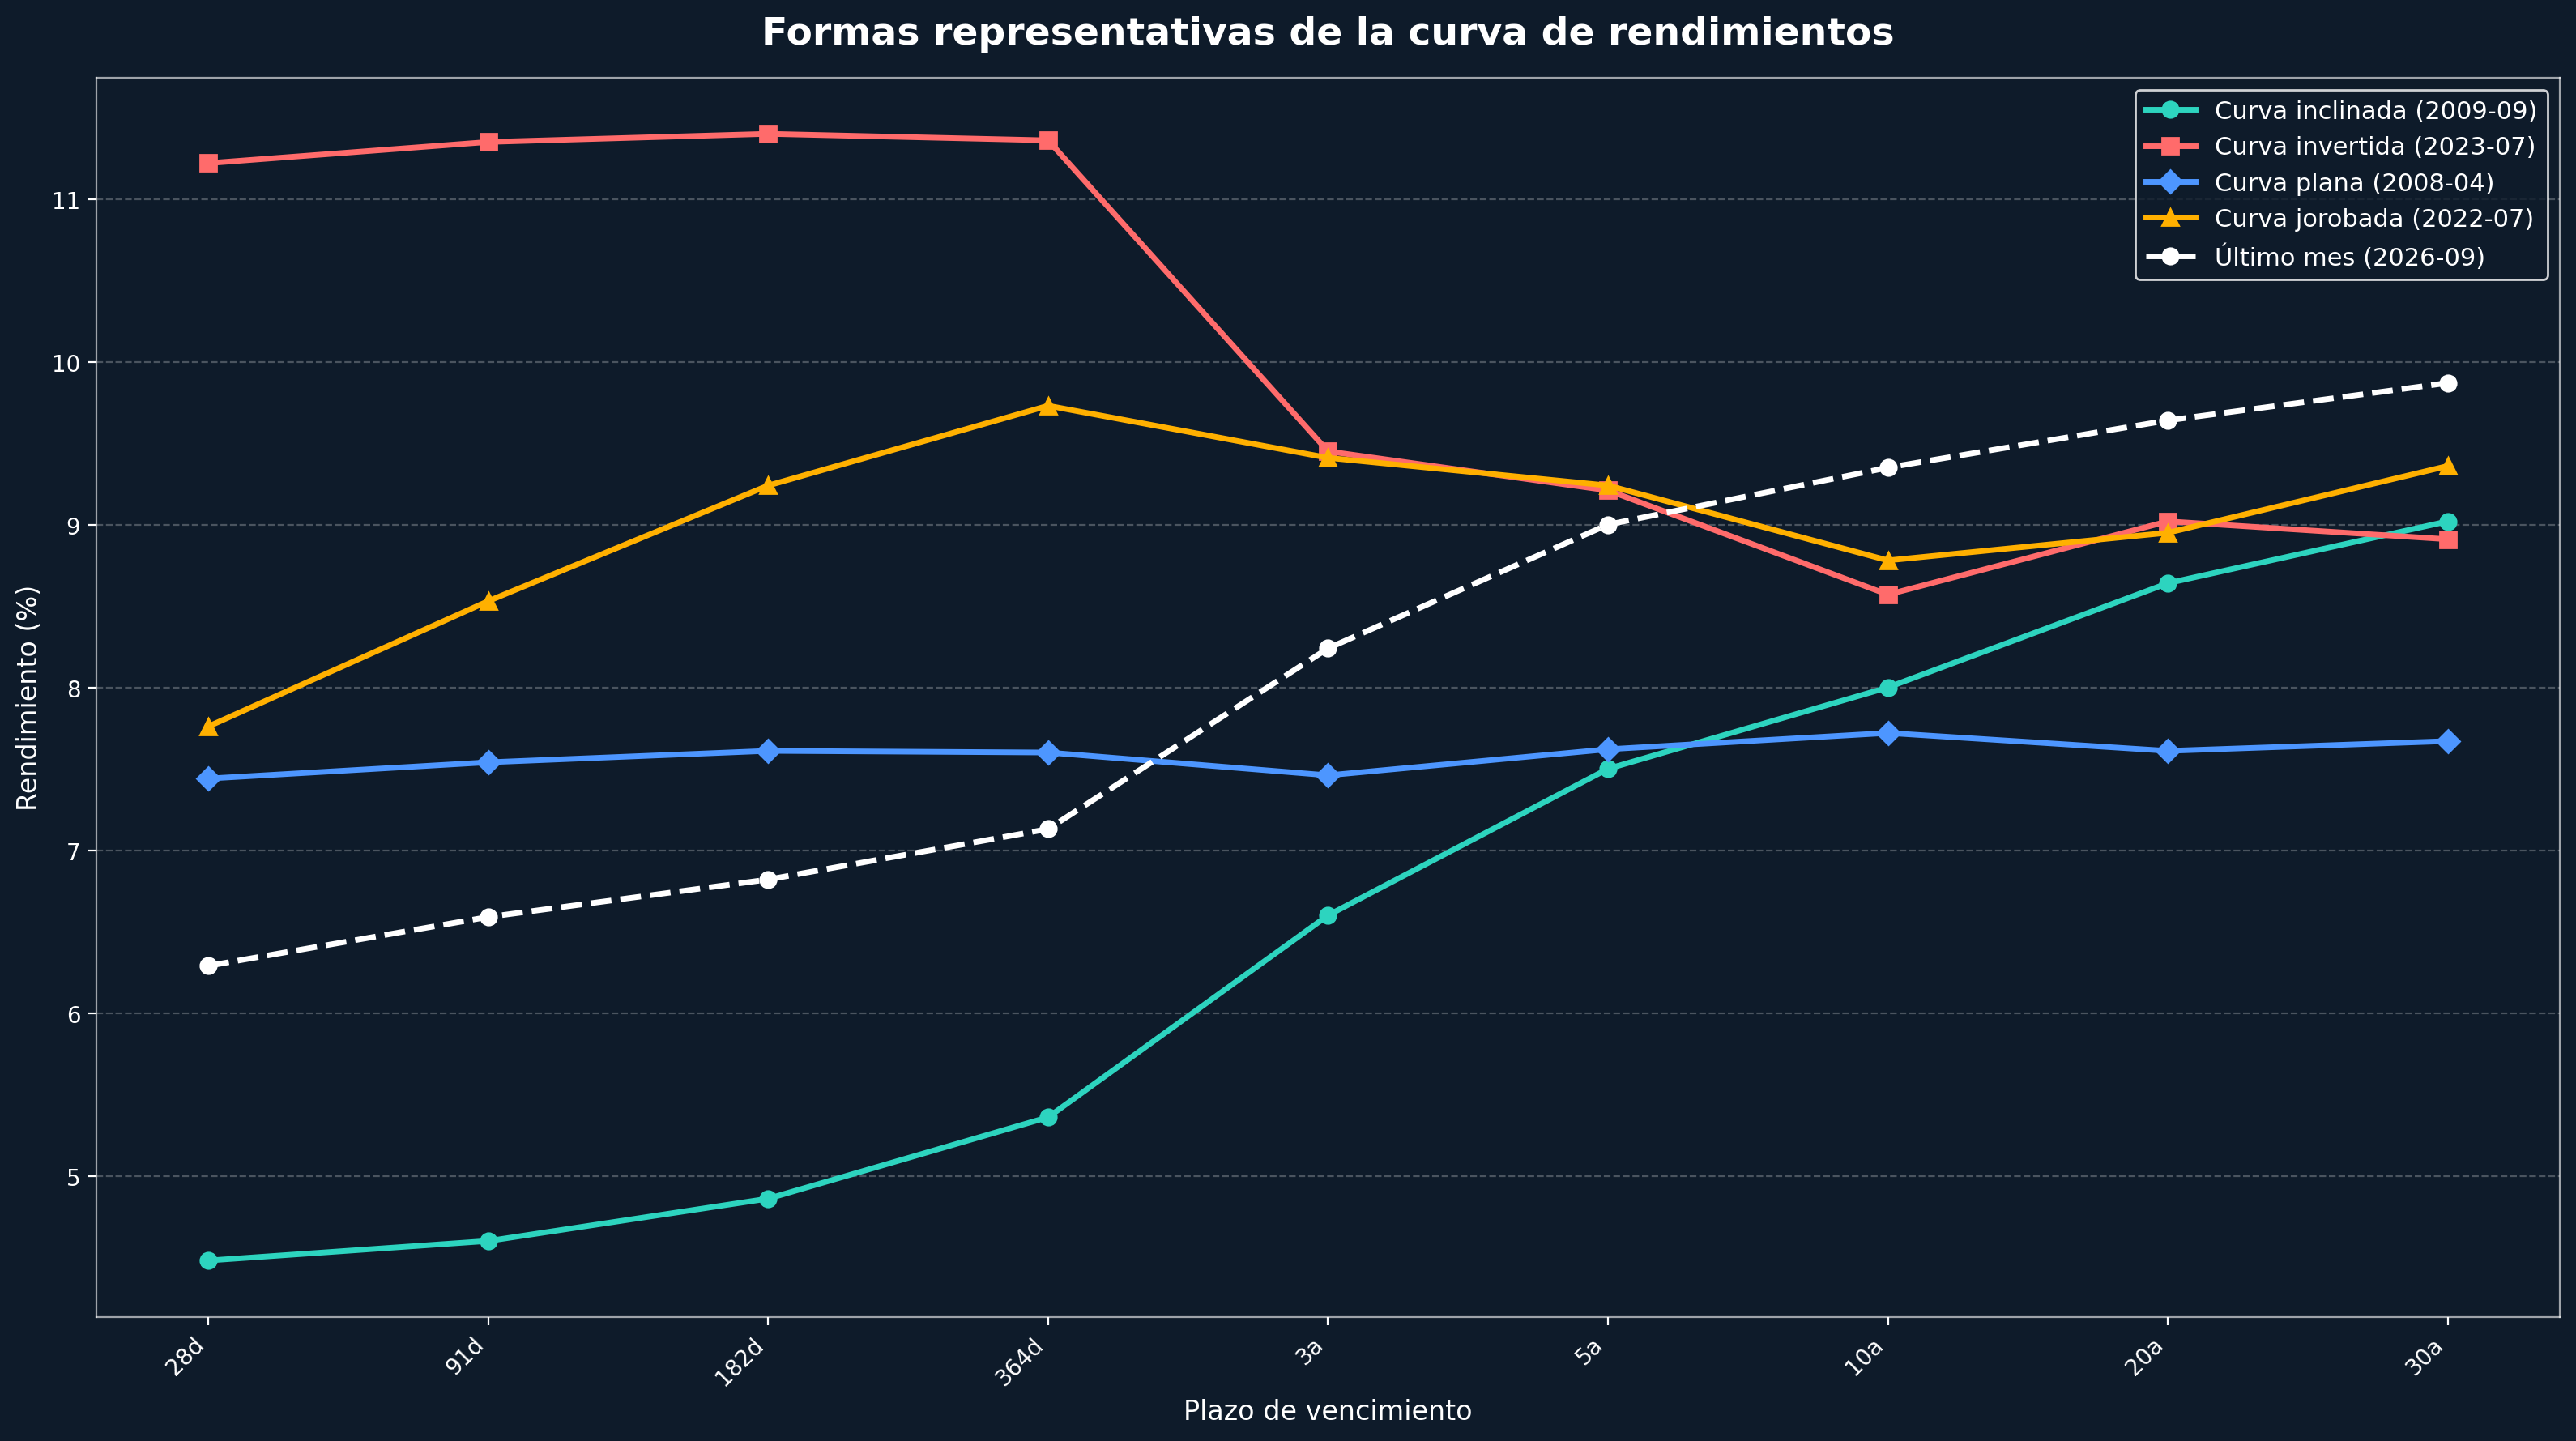

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Preparar la base
# ============================================================

PROCESSED_CURVES_PATH = PROJECT_DIR / "data" / "processed" / "tasas_mensuales_forward_fill.csv"
tasas_mensuales_forward_fill = pd.read_csv(
    PROCESSED_CURVES_PATH,
    parse_dates=["mes"],
).set_index("mes")

plazos = [
    "28d", "91d", "182d", "364d",
    "3a", "5a", "10a", "20a", "30a"
]

datos_curvas = tasas_mensuales_forward_fill[plazos].copy()

datos_curvas.index = pd.to_datetime(
    datos_curvas.index
)

datos_curvas = (
    datos_curvas
    .sort_index()
    .ffill()
    .dropna()
)
# ============================================================
# 2. Medidas de forma de la curva
# ============================================================

# Pendiente normal:
# tasa larga menos tasa corta
datos_curvas["pendiente"] = (
    datos_curvas["30a"] - datos_curvas["28d"]
)

# Pendiente invertida:
# tasa corta menos tasa larga
datos_curvas["pendiente_invertida"] = (
    datos_curvas["28d"] - datos_curvas["30a"]
)

# Amplitud total de cada curva
amplitud_curva = (
    datos_curvas[plazos].max(axis=1)
    - datos_curvas[plazos].min(axis=1)
)

# ============================================================
# 3. Seleccionar una curva inclinada
# ============================================================

fecha_inclinada = (
    datos_curvas["pendiente"].idxmax()
)

# ============================================================
# 4. Seleccionar una curva invertida
# ============================================================

fecha_invertida = (
    datos_curvas["pendiente_invertida"].idxmax()
)

# ============================================================
# 5. Seleccionar una curva plana
# ============================================================

# La curva plana es la que presenta menor diferencia
# entre su tasa máxima y su tasa mínima.
fecha_plana = amplitud_curva.idxmin()

# ============================================================
# 6. Seleccionar una curva jorobada en el centro
# ============================================================

# La joroba debe concentrarse en el tramo 364d--3a--5a.
# Se busca un bloque central elevado, no un pico aislado en 10a.
plazos_joroba = ["364d", "3a", "5a"]
plazos_exteriores = ["28d", "10a", "20a", "30a"]

# La curva debe subir desde los plazos cortos hasta 364 días.
sube_hasta_364d = (
    datos_curvas[["28d", "91d", "182d", "364d"]]
    .diff(axis=1)
    .iloc[:, 1:]
    .ge(0)
    .all(axis=1)
)

# Después del bloque central, la curva debe caer hacia 10 años.
cae_despues_de_5a = datos_curvas["5a"] > datos_curvas["10a"]

nivel_bloque_joroba = datos_curvas[plazos_joroba].mean(axis=1)
nivel_exterior = datos_curvas[plazos_exteriores].mean(axis=1)
amplitud_bloque = (
    datos_curvas[plazos_joroba].max(axis=1)
    - datos_curvas[plazos_joroba].min(axis=1)
)

# Se premia un bloque central alto y relativamente compacto.
puntaje_joroba = (
    nivel_bloque_joroba
    - nivel_exterior
    - 0.5 * amplitud_bloque
).where(sube_hasta_364d & cae_despues_de_5a)

fecha_jorobada = puntaje_joroba.idxmax()
plazo_pico_joroba = datos_curvas.loc[
    fecha_jorobada, plazos_joroba
].idxmax()

print(
    "Bloque central seleccionado:",
    ", ".join(plazos_joroba),
    "| pico:",
    plazo_pico_joroba,
    "| contraste:",
    round((nivel_bloque_joroba - nivel_exterior).loc[fecha_jorobada], 2),
    "puntos porcentuales",
)

# ============================================================
# 7. Último mes observado
# ============================================================

fecha_ultimo_mes = datos_curvas.index.max()

# ============================================================
# 8. Fechas seleccionadas
# ============================================================

fechas_seleccionadas = {
    "Curva inclinada": fecha_inclinada,
    "Curva invertida": fecha_invertida,
    "Curva plana": fecha_plana,
    "Curva jorobada": fecha_jorobada,
    "Último mes": fecha_ultimo_mes
}

print("Fechas seleccionadas:\n")

for tipo, fecha in fechas_seleccionadas.items():
    print(
        f"- {tipo}: {fecha.strftime('%Y-%m')}"
    )

# ============================================================
# 9. Tabla de tasas de las curvas seleccionadas
# ============================================================

tabla_curvas = pd.DataFrame({
    tipo: datos_curvas.loc[fecha, plazos]
    for tipo, fecha in fechas_seleccionadas.items()
}).T

tabla_curvas.index.name = "Tipo de curva"

print("\nTasas por plazo:")
display(tabla_curvas.round(2))

# ============================================================
# 10. Colores y marcadores
# ============================================================

colores = {
    "Curva inclinada": "#2DD4BF",
    "Curva invertida": "#FF6B6B",
    "Curva plana": "#4D96FF",
    "Curva jorobada": "#FFB000",
    "Último mes": "#FFFFFF"
}

marcadores = {
    "Curva inclinada": "o",
    "Curva invertida": "s",
    "Curva plana": "D",
    "Curva jorobada": "^",
    "Último mes": "o"
}

# ============================================================
# 11. Graficar las curvas
# ============================================================

plt.close("all")

fig, ax = plt.subplots(
    figsize=(16, 9),
    dpi=200
)

fig.patch.set_facecolor("#0E1B2A")
ax.set_facecolor("#0E1B2A")

for tipo, fecha in fechas_seleccionadas.items():

    if tipo == "Último mes":
        ax.plot(
            plazos,
            datos_curvas.loc[fecha, plazos],
            color=colores[tipo],
            linestyle="--",
            marker=marcadores[tipo],
            markersize=7,
            linewidth=2.5,
            label=(
                f"{tipo} "
                f"({fecha.strftime('%Y-%m')})"
            ),
            zorder=10
        )

    else:
        ax.plot(
            plazos,
            datos_curvas.loc[fecha, plazos],
            color=colores[tipo],
            linestyle="-",
            marker=marcadores[tipo],
            markersize=7,
            linewidth=2.5,
            label=(
                f"{tipo} "
                f"({fecha.strftime('%Y-%m')})"
            ),
            zorder=5
        )

# ============================================================
# 12. Formato del gráfico
# ============================================================

ax.set_title(
    "Formas representativas de la curva de rendimientos",
    fontsize=17,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel(
    "Plazo de vencimiento",
    fontsize=12,
    color="white"
)

ax.set_ylabel(
    "Rendimiento (%)",
    fontsize=12,
    color="white"
)

ax.set_xticks(range(len(plazos)))
ax.set_xticklabels(
    plazos,
    rotation=45,
    ha="right"
)

ax.tick_params(
    axis="both",
    colors="white",
    labelsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    color="white",
    alpha=0.25
)

for borde in ax.spines.values():
    borde.set_color("white")
    borde.set_alpha(0.6)

ax.legend(
    fontsize=11,
    loc="best",
    frameon=True,
    facecolor="#0E1B2A",
    edgecolor="white",
    labelcolor="white"
)

plt.tight_layout()

# ============================================================
# 13. Guardar en alta resolución
# ============================================================

output_dir = "outputs/figures"

plt.savefig(
    f"{output_dir}/curvas_representativas.png",
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.savefig(
    f"{output_dir}/curvas_representativas.pdf",
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

### Interpretación de las formas observadas

Según la teoría, una curva de rendimientos puede adoptar cuatro formas principales:

1. **Normal o ascendente (*upward sloping*):** las tasas cortas son menores que las largas; suele reflejar el comportamiento "normal" en el entorno macroeconómico. En la figura superior, la curva de septiembre (verde) 2009 y septiembre 2026 (blanca punteada), son ejemplos de este tipo de curva. Un claro ejemplo es la curva de julio 2023 (roja)
2. **Invertida (*downward sloping*):** las tasas cortas son mayores que las largas. Puede aparecer cuando el banco central ha endurecido la política monetaria y el mercado espera tasas menores en el futuro. Un ejemplo claro es la curva de julio 2023 (roja): para ese momento, Banxico ya había llegado al pico de su ciclo de alzas (11.25%, alcanzado en marzo de 2023, como parte de la respuesta a la inflación post-pandemia de 2021-2023) y mantenía la tasa en ese nivel. Al haber tasas cortas muy altas y sostenidas, la expectativa de mercado era que, eventualmente, tendrían que bajar.
3. **Plana (*flat*):** las tasas cortas y largas son muy parecidas; suele observarse en periodos de transición. Un ejemplo claro es la curva de abril 2008, cuando México estaba en un "periodo de calma" relativo antes de la crisis financiera global.
4. **Jorobada (*humped*):** las tasas de plazo medio son mayores que las cortas y las largas. El ejemplo más cercano en la figura anterior  es la de julio 2022, y tiene sentido además en términos de contexto: julio de 2022 cae en medio del ciclo de alzas agresivas de Banxico, un entorno típico para que el tramo corto/medio se infle por expectativas de más alzas inminentes, mientras el tramo largo refleja ya la expectativa de que la tasa eventualmente cederá — generando precisamente esa joroba.

La inspección de la curva de rendimientos muestra por qué no basta con analizar un solo plazo: la curva puede cambiar simultáneamente de nivel, pendiente y curvatura. Esto es justamente lo que se formaliza a continuación mediante PCA.

## Módulo 3 — Estructura de la curva mediante PCA

**¿Existe una estructura común en la forma en que se mueven los nueve plazos?**

Para responder a la primera pregunta del ejercicio se utiliza el Análisis de Componentes Principales (PCA, por sus siglas en inglés). El PCA es un método que permite resumir la variación conjunta de múltiples dimensiones (en este caso las columnas o variables del dataset, es decir, los nueve plazos) en un número menor de factores comunes. Si unos pocos componentes logran explicar la mayor parte de esa variación conjunta, esto es evidencia de que existe una estructura común subyacente a los nueve plazos; si, por el contrario, se necesitaran casi todos los componentes para explicar la variación, eso indicaría que los plazos se mueven de forma mayormente independiente. Esta reducción, además, facilita la interpretación de la curva al resumir su comportamiento en pocos factores en vez de nueve series por separado.

Cada componente principal es como un promedio ponderado de los nueve plazos, donde el peso que recibe cada plazo se llama **carga** (*loading*). La carga indica si un plazo empuja al componente hacia arriba o hacia abajo, y con qué fuerza; el patrón de cargas en conjunto es lo que le da forma a cada componente (nivel, pendiente o curvatura). Asimismo, el método permite identificar la **varianza explicada** por componente, lo cual indica qué tan importante es cada uno para resumir el movimiento conjunto de toda la curva.

Una cuestión importante fue decidir si el PCA se aplicaba sobre niveles (la tasa tal cual se reporta mes a mes en el dataset), o sobre los cambios (la diferencia de las tasas en cada plazo mes a mes). Después de una deliveración profunda y análizar el impacto de información faltante, se optó por aplicar el PCA únicamente sobre los niveles, los cuales describen la forma de la curva en cada mes, respondiendo de forma más directa a encontrar la “estructura de la curva”. Los cambios, por otro lado, describen cómo se mueve esa forma en el tiempo, que es otra pregunta.

La respuesta se construye en cinco pasos dentro de este módulo:

1. Exploración inicial y cálculo de correlaciones
2. Estimar el PCA sobre niveles.
3. Interpretar los componentes.
4. Validar y visualizar los resultados.


### Paso 1 — Exploración inicial
Se examinan las correlaciones entre los nueve plazos y su patrón conjunto antes de estimar el PCA.

In [43]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA requiere una matriz completa: se excluye solo la fila inicial con el NaN decidido.
# Forward-fill solo hacia adelante, sin backfill ni usar información futura.
tasas_mensuales_forward_fill = tasas_mensuales_por_plazo.ffill().copy()

# PCA requiere una matriz completa: se excluye solo la fila inicial con NaN
# y cualquier otra fila que siga teniendo faltantes después del fill.
matriz_pca_niveles = tasas_mensuales_forward_fill.dropna().copy()
print(matriz_pca_niveles.head(5))
print('Meses usadas en PCA:', matriz_pca_niveles.shape[0])
print('Plazos usados:', matriz_pca_niveles.shape[1])
print('Faltantes en matriz PCA:', int(matriz_pca_niveles.isna().sum().sum()))

             28d   91d  182d  364d    3a    5a   10a   20a   30a
mes                                                             
2006-11-01  7.04  7.16  7.26  7.28  7.39  7.50  7.88  7.95  8.08
2006-12-01  7.04  7.16  7.20  7.27  7.18  7.28  7.56  7.57  8.08
2007-01-01  7.04  7.19  7.31  7.46  7.70  7.52  7.43  7.93  8.08
2007-02-01  7.04  7.19  7.34  7.38  7.47  7.70  7.96  7.93  7.71
2007-03-01  7.04  7.21  7.38  7.52  7.52  7.69  7.82  7.99  7.71
Meses usadas en PCA: 239
Plazos usados: 9
Faltantes en matriz PCA: 0


,28d,91d,182d,364d,3a,5a,10a,20a,30a
28d,1.00,1.00,0.99,0.98,0.94,0.89,0.83,0.76,0.73
91d,1.00,1.00,1.00,0.99,0.95,0.90,0.84,0.77,0.74
182d,0.99,1.00,1.00,1.00,0.96,0.91,0.85,0.78,0.74
364d,0.98,0.99,1.00,1.00,0.97,0.93,0.87,0.79,0.76
3a,0.94,0.95,0.96,0.97,1.00,0.97,0.93,0.86,0.83
5a,0.89,0.90,0.91,0.93,0.97,1.00,0.96,0.91,0.88
10a,0.83,0.84,0.85,0.87,0.93,0.96,1.00,0.95,0.93
20a,0.76,0.77,0.78,0.79,0.86,0.91,0.95,1.00,0.95
30a,0.73,0.74,0.74,0.76,0.83,0.88,0.93,0.95,1.00


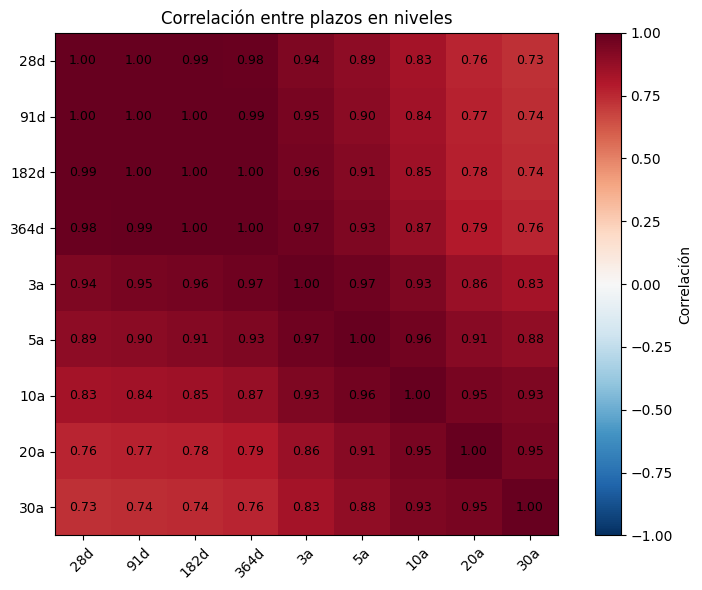

In [44]:
#calcular correlaciones con los niveles de los plazos
correlacion_niveles = matriz_pca_niveles.corr()
display(correlacion_niveles.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlacion_niveles, vmin=-1, vmax=1, cmap='RdBu_r')

ax.set_xticks(
    range(len(matriz_pca_niveles.columns)),
    matriz_pca_niveles.columns,
    rotation=45
)
ax.set_yticks(
    range(len(matriz_pca_niveles.columns)),
    matriz_pca_niveles.columns
)

# Escribir cada correlación dentro de su celda
for fila in range(len(correlacion_niveles)):
    for columna in range(len(correlacion_niveles.columns)):
        valor = correlacion_niveles.iloc[fila, columna]
        ax.text(
            columna,
            fila,
            f"{valor:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

ax.set_title('Correlación entre plazos en niveles')
fig.colorbar(im, ax=ax, label='Correlación')
plt.tight_layout()
plt.show()

#### Paso 1.1 — Validación cruzada con solo los 40 meses completos
Con fines de comprobación y descartar que la alta correlación observada en la base de 239 meses no se deba al forward-fill, se recalculó la matriz usando únicamente los meses con datos originales completos para los nueve plazos (40 meses), sin imputar valores. Esta comparación permite verificar si la relación entre las tasas también está presente en las observaciones efectivamente disponibles. 

Nota: la matriz con los 239 meses es la que se mantiene para el análisis, no la de 40.



Meses completos utilizados: 40
Periodo: 2007-08-01 00:00:00 a 2026-07-01 00:00:00


,28d,91d,182d,364d,3a,5a,10a,20a,30a
28d,1.00,1.00,0.99,0.98,0.91,0.87,0.81,0.73,0.70
91d,1.00,1.00,1.00,0.99,0.93,0.89,0.82,0.74,0.71
182d,0.99,1.00,1.00,1.00,0.95,0.90,0.84,0.75,0.72
364d,0.98,0.99,1.00,1.00,0.96,0.92,0.86,0.77,0.74
3a,0.91,0.93,0.95,0.96,1.00,0.98,0.94,0.87,0.84
5a,0.87,0.89,0.90,0.92,0.98,1.00,0.96,0.92,0.89
10a,0.81,0.82,0.84,0.86,0.94,0.96,1.00,0.96,0.95
20a,0.73,0.74,0.75,0.77,0.87,0.92,0.96,1.00,0.97
30a,0.70,0.71,0.72,0.74,0.84,0.89,0.95,0.97,1.00


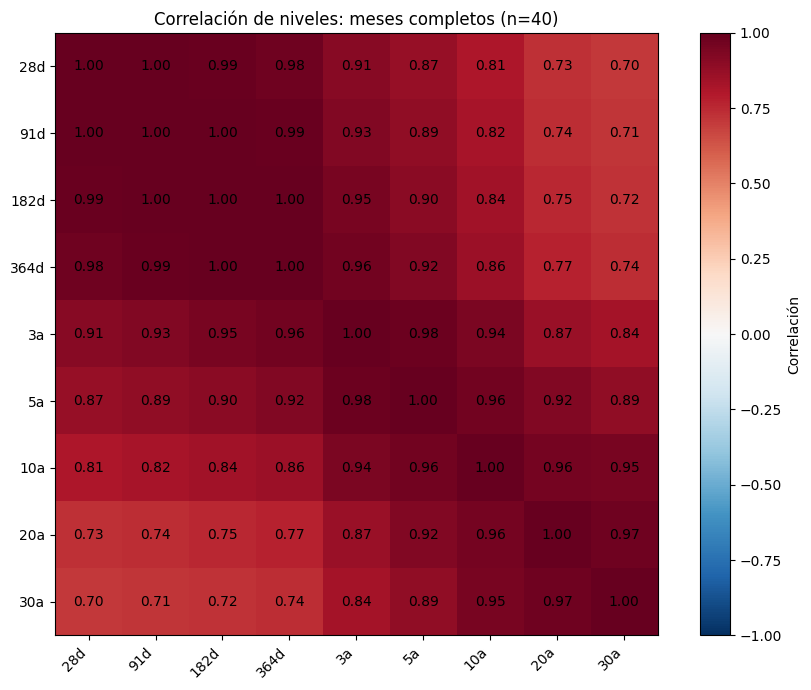

In [45]:
# Correlación de niveles usando solo meses completos de la base original
plazos = [
    "28d", "91d", "182d", "364d",
    "3a", "5a", "10a", "20a", "30a"
]

# Seleccionar los nueve plazos sin aplicar forward-fill
niveles_originales = tasas_mensuales_por_plazo.loc[:, plazos].copy()

# Conservar únicamente los meses con datos observados en los nueve plazos
niveles_completos = niveles_originales.dropna(how="any")

print("Meses completos utilizados:", len(niveles_completos))
print("Periodo:", niveles_completos.index.min(), "a", niveles_completos.index.max())

# Correlación entre los niveles de las tasas
correlacion_niveles_completos = niveles_completos.corr()

display(correlacion_niveles_completos.round(2))

# Visualizar la matriz de correlaciones
fig, ax = plt.subplots(figsize=(9, 7))

imagen = ax.imshow(
    correlacion_niveles_completos,
    vmin=-1,
    vmax=1,
    cmap="RdBu_r"
)

ax.set_xticks(range(len(plazos)))
ax.set_xticklabels(plazos, rotation=45, ha="right")
ax.set_yticks(range(len(plazos)))
ax.set_yticklabels(plazos)

# Mostrar cada coeficiente dentro de la celda
for fila in range(len(plazos)):
    for columna in range(len(plazos)):
        ax.text(
            columna,
            fila,
            f"{correlacion_niveles_completos.iloc[fila, columna]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(imagen, ax=ax, label="Correlación")
ax.set_title(
    f"Correlación de niveles: meses completos (n={len(niveles_completos)})"
)
fig.tight_layout()
plt.show()

**Resultado de la exploración**

En los 239 meses con forward-fill, las correlaciones entre plazos son positivas y altas (mínimo de 0.73 entre 28 días y 30 años). Al repetir el cálculo solo con los 40 meses completos de la base original, sin imputación, las correlaciones también son altas y positivas (mínimo de 0.70 entre 28 días y 30 años). Esto sugiere que la relación entre los plazos no se debe únicamente al forward-fill.





### Paso 2 — Aplicación del PCA a niveles

#### 2.1 Definir la matriz y el tratamiento de las variables
Se utilizan las nueve tasas en niveles, expresadas en la misma unidad (porcentaje). `PCA` centra cada columna al estimar el modelo; no se estandarizan las tasas, por lo que el análisis conserva las diferencias de volatilidad entre plazos.

In [46]:
print('Observaciones usadas:', matriz_pca_niveles.shape[0])
print('Plazos usados:', matriz_pca_niveles.shape[1])
print('Faltantes en matriz PCA:', int(matriz_pca_niveles.isna().sum().sum()))

Observaciones usadas: 239
Plazos usados: 9
Faltantes en matriz PCA: 0


#### 2.2 Ajustar el PCA y calcular los puntajes
Se estima el modelo con todos los componentes. Los puntajes (*scores*) son las coordenadas de cada mes en los nuevos ejes principales.

In [47]:
# Ajuste del PCA en niveles y puntajes mensuales.
pca_niveles = PCA()
scores_niveles = pca_niveles.fit_transform(matriz_pca_niveles)
print('Dimensiones de los puntajes:', scores_niveles.shape)

Dimensiones de los puntajes: (239, 9)


#### 2.3 Medir la varianza explicada
Se reportan la varianza explicada individual y acumulada para decidir cuántos componentes resumen adecuadamente la curva.

In [48]:
varianza_niveles = pd.DataFrame({
    'componente': [f'PC{i}' for i in range(1, len(pca_niveles.explained_variance_ratio_) + 1)],
    'varianza_explicada': pca_niveles.explained_variance_ratio_,
    'varianza_acumulada': pca_niveles.explained_variance_ratio_.cumsum(),
}, index=range(1, len(pca_niveles.explained_variance_ratio_) + 1))
varianza_niveles.index.name = 'numero_componente'
print('Varianza explicada acumulada por los primeros 3 componentes:', round(varianza_niveles['varianza_acumulada'].iloc[2], 4))
display(varianza_niveles.round(4))

Varianza explicada acumulada por los primeros 3 componentes: 0.9938


,componente,varianza_explicada,varianza_acumulada
numero_componente,,,
1,PC1,0.9409,0.9409
2,PC2,0.0460,0.9869
3,PC3,0.0069,0.9938
4,PC4,0.0018,0.9957
5,PC5,0.0018,0.9974
6,PC6,0.0014,0.9989
7,PC7,0.0010,0.9998
8,PC8,0.0001,1.0000
9,PC9,0.0000,1.0000


#### 2.4 Revisar las cargas
Las cargas (*loadings*) muestran el peso de cada plazo en cada componente. Se muestran las nueve para los primeros tres componentes. El signo de un componente puede invertirse sin cambiar la solución.

In [49]:
cargas_niveles = pd.DataFrame(
    pca_niveles.components_.T,
    index=matriz_pca_niveles.columns,
    columns=[f"PC{i}" for i in range(1, matriz_pca_niveles.shape[1] + 1)],
)
display(cargas_niveles.iloc[:, :3].round(4))

,PC1,PC2,PC3
28d,0.4169,-0.2895,-0.3823
91d,0.4258,-0.2675,-0.1936
182d,0.4277,-0.2323,-0.0008
364d,0.4240,-0.1529,0.2010
3a,0.3176,0.1684,0.5352
5a,0.2779,0.3363,0.4088
10a,0.2181,0.4338,0.0249
20a,0.1754,0.4664,-0.3299
30a,0.1608,0.4691,-0.4615


#### 2.5 Revisar el error
Para evaluar qué tan bien los componentes representan la curva, se compara el RMSE entre las tasas observadas y las reconstruidas usando distintas cantidades de componentes.

In [50]:
errores_reconstruccion = []
for k in range(1, matriz_pca_niveles.shape[1] + 1):
    modelo_k = PCA(n_components=k)
    scores_k = modelo_k.fit_transform(matriz_pca_niveles)
    reconstruida = modelo_k.inverse_transform(scores_k)
    rmse = np.sqrt(np.mean((matriz_pca_niveles.to_numpy() - reconstruida) ** 2))
    errores_reconstruccion.append({'componentes': k, 'RMSE_porcentuales': rmse, 'RMSE_puntos_base': rmse * 100})

errores_reconstruccion = pd.DataFrame(errores_reconstruccion)
display(errores_reconstruccion.round(4))

,componentes,RMSE_porcentuales,RMSE_puntos_base
0,1,0.4664,46.6431
1,2,0.2194,21.9438
2,3,0.1507,15.0739
3,4,0.1262,12.6152
4,5,0.0969,9.6941
5,6,0.0645,6.4491
6,7,0.0254,2.5414
7,8,0.0101,1.0112
8,9,0.0000,0.0000


### Paso 3 — Interpretación

Litterman y Scheinkman (1991) documentaron que, al aplicar PCA sobre retornos de bonos del Tesoro de EE.UU., los primeros tres componentes suelen identificarse con **nivel**, **pendiente** y **curvatura** (el marco de referencia para entender el movimiento en curvas de rendimiento). Las cargas obtenidas aquí siguen ese patrón.

**PC1 — Nivel (explica el 94.09% de la variabilidad por lo que es el primer principal componente):** muestra cargas positivas en los nueve plazos, de 0.42 en 28 días a 0.16 en 30 años — mayores en el corto plazo. Cuando sube, toda la curva sube junta. Diebold, Rudebusch y Aruoba (2006) lo asocian con expectativas de inflación de largo plazo.

**PC2 — Pendiente (4.60%, acumulado 98.69%):** cargas negativas en plazos cortos (−0.29 en 28d) y positivas en largos (0.47 en 30a). Un puntaje alto implica curva más empinada. Se suele ligar al ciclo económico y a la política monetaria.

**PC3 — Curvatura (0.69%, acumulado 99.38%):** cargas negativas en los extremos (−0.38 y −0.46) y positivas en el tramo medio (0.54 en 3a). A diferencia del nivel y la pendiente, la curvatura no tiene consenso macroeconómico establecido.

**En conjunto, estos tres factores interpretables explican el 99.38% del movimiento conjunto de los nueve plazos — respondiendo directamente a la Pregunta 1: sí existe una estructura común y compacta en cómo se mueve la curva mexicana, consistente con la literatura internacional. Esto además prepara la Pregunta 2: como el nivel es mucho más persistente que la pendiente y la curvatura, es razonable esperar que la facilidad de pronóstico dependa del horizonte y de la representación elegida.**


### Paso 4 — Validación y visualizaciones del PCA en niveles
Se comparan los puntajes con las tasas observadas y se revisan sus patrones a lo largo del tiempo.

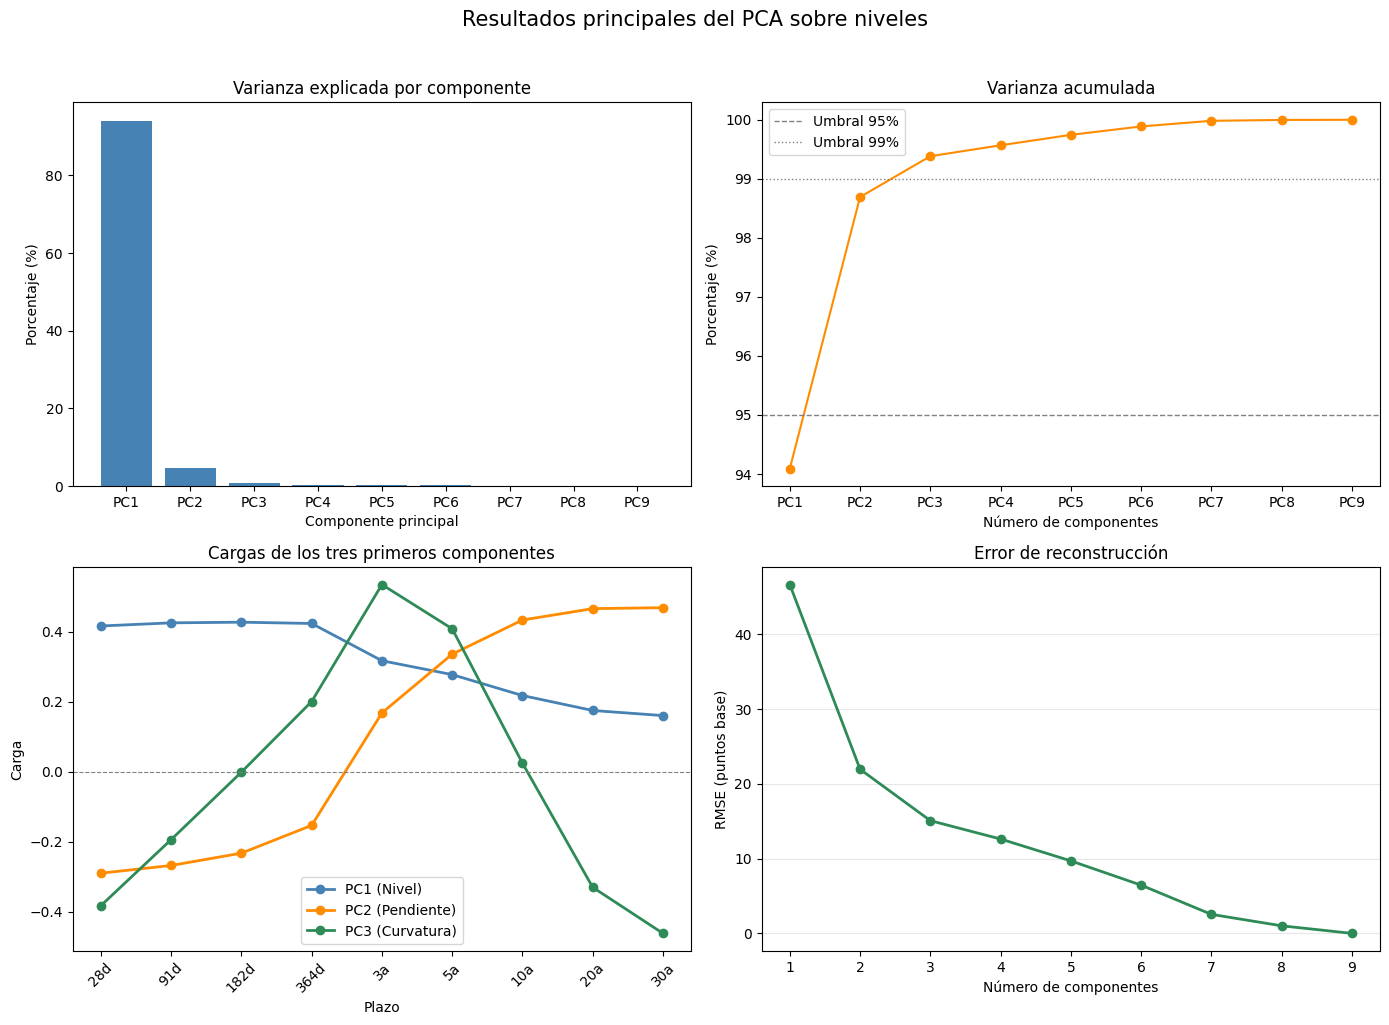

In [51]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --------------------------------------------------
# 1. Varianza explicada
# --------------------------------------------------

varianza = varianza_niveles  # alias para compatibilidad con el resto del bloque
axes[0, 0].bar(
    varianza["componente"],
    varianza["varianza_explicada"] * 100,
    color="steelblue"
)

axes[0, 0].set_title("Varianza explicada por componente")
axes[0, 0].set_xlabel("Componente principal")
axes[0, 0].set_ylabel("Porcentaje (%)")
axes[0, 0].set_xticks(varianza["componente"])

# --------------------------------------------------
# 2. Varianza acumulada
# --------------------------------------------------

axes[0, 1].plot(
    varianza["componente"],
    varianza["varianza_acumulada"] * 100,
    marker="o",
    color="darkorange"
)

axes[0, 1].axhline(
    95,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Umbral 95%"
)

axes[0, 1].axhline(
    99,
    color="gray",
    linestyle=":",
    linewidth=1,
    label="Umbral 99%"
)

axes[0, 1].set_title("Varianza acumulada")
axes[0, 1].set_xlabel("Número de componentes")
axes[0, 1].set_ylabel("Porcentaje (%)")
axes[0, 1].set_xticks(varianza["componente"])
axes[0, 1].legend()

# --------------------------------------------------
# 3. Cargas de los tres primeros componentes
# --------------------------------------------------

etiquetas_componentes = {
    "PC1": "PC1 (Nivel)",
    "PC2": "PC2 (Pendiente)",
    "PC3": "PC3 (Curvatura)"
}

colores_componentes = {
    "PC1": "steelblue",
    "PC2": "darkorange",
    "PC3": "seagreen"
}

for componente, etiqueta in etiquetas_componentes.items():
    axes[1, 0].plot(
        cargas_niveles.index,
        cargas_niveles[componente],
        marker="o",
        linewidth=2,
        color=colores_componentes[componente],
        label=etiqueta
    )

axes[1, 0].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=0.8
)

axes[1, 0].set_title("Cargas de los tres primeros componentes")
axes[1, 0].set_xlabel("Plazo")
axes[1, 0].set_ylabel("Carga")
axes[1, 0].legend()
axes[1, 0].tick_params(axis="x", rotation=45)

# --------------------------------------------------
# 4. Error de reconstrucción
# --------------------------------------------------

axes[1, 1].plot(
    errores_reconstruccion["componentes"],
    errores_reconstruccion["RMSE_puntos_base"],
    marker="o",
    linewidth=2,
    color="seagreen"
)

axes[1, 1].set_title("Error de reconstrucción")
axes[1, 1].set_xlabel("Número de componentes")
axes[1, 1].set_ylabel("RMSE (puntos base)")
axes[1, 1].set_xticks(
    errores_reconstruccion["componentes"]
)
axes[1, 1].grid(axis="y", alpha=0.3)

# --------------------------------------------------
# Formato final
# --------------------------------------------------

fig.suptitle(
    "Resultados principales del PCA sobre niveles",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

**Lectura de la figura**

- **Varianza explicada (arriba-izq.):** PC1 domina con 94.1% — la mayor parte del movimiento conjunto de la curva es un solo factor común.
- **Varianza acumulada (arriba-der.):** se cruza el umbral de 95% ya con 2 componentes (98.7%) y el de 99% con 3 (99.4%). A partir de ahí, cada componente adicional aporta menos del 0.2% — señal de que la estructura está en 3 componentes.
- **Cargas (abajo-izq.):** confirma la interpretación estándar de la literatura (Litterman y Scheinkman, 1991) — PC1 (nivel) con cargas uniformemente positivas, mayores en el corto plazo; PC2 (pendiente) cambia de signo entre corto y largo plazo; PC3 (curvatura) cambia de signo dos veces, con un máximo en el tramo medio (3a-5a).
- **Error de reconstrucción (abajo-der.):** cae de 46.6 pb con 1 componente a 15.1 pb con 3 — consistente con la varianza acumulada, y confirma que agregar más de 3 componentes ya no reduce el error de forma relevante.

Observaciones comparables: 220


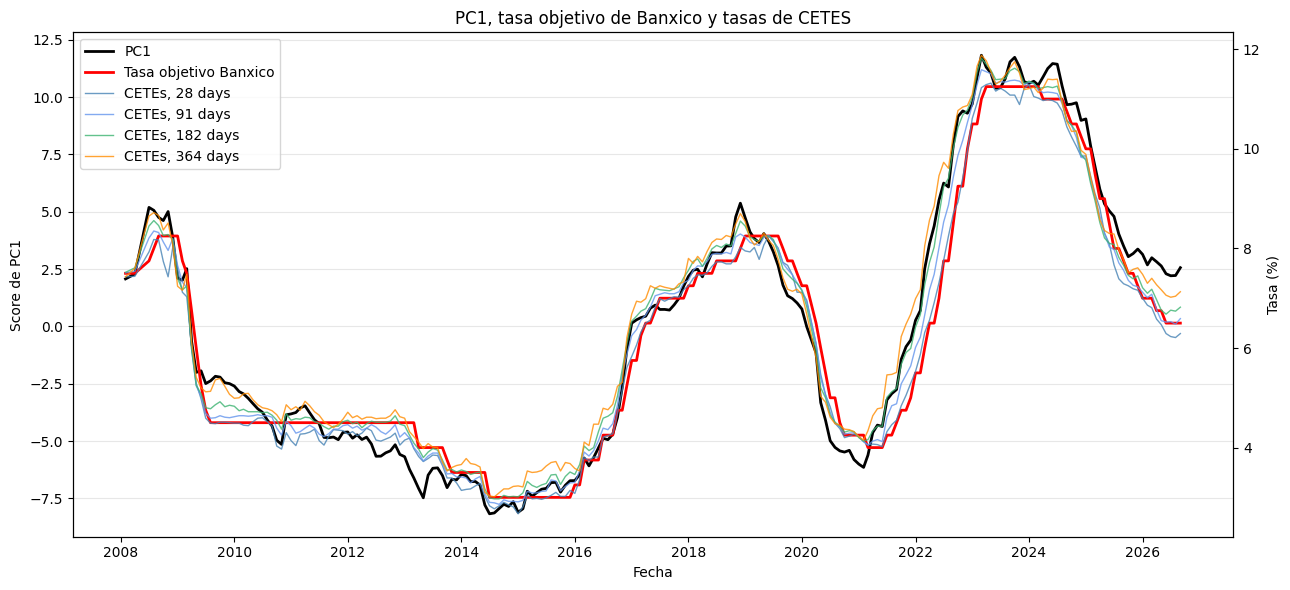

Correlaciones con PC1:


,Pearson
Tasa objetivo Banxico,0.9768
"CETEs, 28 days",0.9842
"CETEs, 91 days",0.9896
"CETEs, 182 days",0.9924
"CETEs, 364 days",0.9943


In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Preparar PC1
# --------------------------------------------------

# Obtener los scores del PCA (si ya se calcularon antes, usarlos; si no, ajustarlos)
if "scores_niveles" in globals():
    scores = scores_niveles
elif hasattr(modelo_k, "components_"):
    scores = modelo_k.transform(matriz_pca_niveles)
else:
    scores = modelo_k.fit_transform(matriz_pca_niveles)

pc1 = pd.Series(
    scores[:, 0],
    index=pd.to_datetime(matriz_pca_niveles.index),
    name="PC1"
)

# --------------------------------------------------
# 2. Preparar tasa objetivo de Banxico
# --------------------------------------------------

# tasa_banxico ya es una Series
# Asegurar que exista la tabla de Banxico y que tenga las columnas esperadas
if "tasa_banxico" not in globals():
    tasa_banxico = pd.read_excel(BANXICO_PATH)

if not isinstance(tasa_banxico, pd.DataFrame):
    tasa_banxico = pd.DataFrame({"SF61745": tasa_banxico})
    tasa_banxico.index.name = "Fecha"
    tasa_banxico = tasa_banxico.reset_index()

tasa_banxico = tasa_banxico.copy()
tasa_banxico.columns = [str(col).strip() for col in tasa_banxico.columns]

if "Fecha" not in tasa_banxico.columns:
    for col in tasa_banxico.columns:
        if str(col).lower() in {"fecha", "date"}:
            tasa_banxico = tasa_banxico.rename(columns={col: "Fecha"})
            break

if "SF61745" not in tasa_banxico.columns:
    candidates = [
        col for col in tasa_banxico.columns
        if "61745" in str(col)
        or "tasa" in str(col).lower()
        or "objetivo" in str(col).lower()
    ]
    if not candidates:
        raise KeyError(
            f"No encontré la columna de tasa objetivo en BANXICO_PATH.\n"
            f"Columnas disponibles: {list(tasa_banxico.columns)}"
        )
    tasa_banxico = tasa_banxico.rename(columns={candidates[0]: "SF61745"})

tasa_banxico = tasa_banxico[["Fecha", "SF61745"]].copy()
tasa_banxico["Fecha"] = pd.to_datetime(tasa_banxico["Fecha"])

tasa_objetivo = tasa_banxico.copy()
tasa_objetivo.index = pd.to_datetime(tasa_objetivo.index)
tasa_objetivo = pd.to_numeric(
    tasa_banxico["SF61745"],
    errors="coerce"
)
tasa_objetivo.index = pd.to_datetime(tasa_banxico["Fecha"])
tasa_objetivo = tasa_objetivo.rename("Tasa objetivo Banxico")

# --------------------------------------------------
# 3. Seleccionar CETES
# --------------------------------------------------

cetes = [
    "CETEs, 28 days",
    "CETEs, 91 days",
    "CETEs, 182 days",
    "CETEs, 364 days"
]

# Verificar que existan las columnas
columnas_faltantes = [
    cete for cete in cetes
    if cete not in matriz_pca_niveles.columns
]

matriz_pca_cetes = matriz_pca_niveles

if columnas_faltantes:
    # Las columnas del PCA usan nombres cortos (28d, 91d, 182d, 364d),
    # mientras que en el resto del notebook se usan los nombres largos.
    # Definir el mapa de columnas cortas -> nombres largos para evitar el NameError
    if "cetes_map" not in globals():
        cetes_map = {
            "28d": "CETEs, 28 days",
            "91d": "CETEs, 91 days",
            "182d": "CETEs, 182 days",
            "364d": "CETEs, 364 days",
            "3a": "MBONOs, 3 years",
            "5a": "MBONOs, 5 years",
            "10a": "MBONOs, 10 years",
            "20a": "MBONOs, 20 years",
            "30a": "MBONOs, 30 years",
        }

    columnas_pca = [k for k, v in cetes_map.items() if v in cetes]
    faltantes = [cetes_map[k] for k in columnas_pca if k not in matriz_pca_niveles.columns]

    if faltantes:
        raise KeyError(
            f"No se encontraron estas columnas: {faltantes}\n"
            f"Columnas disponibles: {matriz_pca_niveles.columns.tolist()}"
        )

    # Seleccionar y renombrar columnas para que coincidan con el resto del código
    matriz_pca_cetes = matriz_pca_niveles[columnas_pca].copy()
    matriz_pca_cetes.columns = [cetes_map[k] for k in columnas_pca]
    cetes = list(matriz_pca_cetes.columns)

# --------------------------------------------------
# 4. Combinar y alinear las series por fecha
# --------------------------------------------------

comparacion = pd.concat(
    [
        pc1,
        tasa_objetivo,
        matriz_pca_cetes[cetes]
    ],
    axis=1
).dropna()

print("Observaciones comparables:", len(comparacion))

# --------------------------------------------------
# 5. Gráfica
# --------------------------------------------------

fig, ax1 = plt.subplots(figsize=(13, 6))

# PC1: eje izquierdo
linea_pc1, = ax1.plot(
    comparacion.index,
    comparacion["PC1"],
    color="black",
    linewidth=2,
    label="PC1"
)

ax1.set_xlabel("Fecha")
ax1.set_ylabel("Score de PC1", color="black")
ax1.tick_params(axis="y", labelcolor="black")
ax1.grid(axis="y", alpha=0.3)

# Tasas: eje derecho
ax2 = ax1.twinx()

lineas_tasas = []

linea_banxico, = ax2.plot(
    comparacion.index,
    comparacion["Tasa objetivo Banxico"],
    color="red",
    linewidth=2,
    label="Tasa objetivo Banxico"
)
lineas_tasas.append(linea_banxico)

colores_cetes = [
    "steelblue",
    "cornflowerblue",
    "mediumseagreen",
    "darkorange"
]

for cete, color in zip(cetes, colores_cetes):
    linea, = ax2.plot(
        comparacion.index,
        comparacion[cete],
        color=color,
        linewidth=1,
        alpha=0.8,
        label=cete
    )
    lineas_tasas.append(linea)

ax2.set_ylabel("Tasa (%)")

ax1.set_title(
    "PC1, tasa objetivo de Banxico y tasas de CETES"
)

# Leyenda conjunta
ax1.legend(
    [linea_pc1] + lineas_tasas,
    ["PC1"] + ["Tasa objetivo Banxico"] + cetes,
    loc="upper left"
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Correlaciones con PC1
# --------------------------------------------------

correlaciones_pc1 = pd.DataFrame({
    "Pearson": comparacion.corr(method="pearson")["PC1"],
}).drop(index="PC1")
print("Correlaciones con PC1:")
display(correlaciones_pc1.round(4))

**Validación empírica del factor de nivel:** dado que PC1 es, por mucho, el componente dominante (94.09% de la varianza total), es clave validar visualmente que su evolución temporal está asociada con la tasa objetivo de Banxico y con las tasas CETES de corto plazo. La correlación de Pearson con la tasa objetivo de Banxico es además de 0.9768, y de entre 0.9842 y 0.9943 frente a las cuatro tasas CETES.

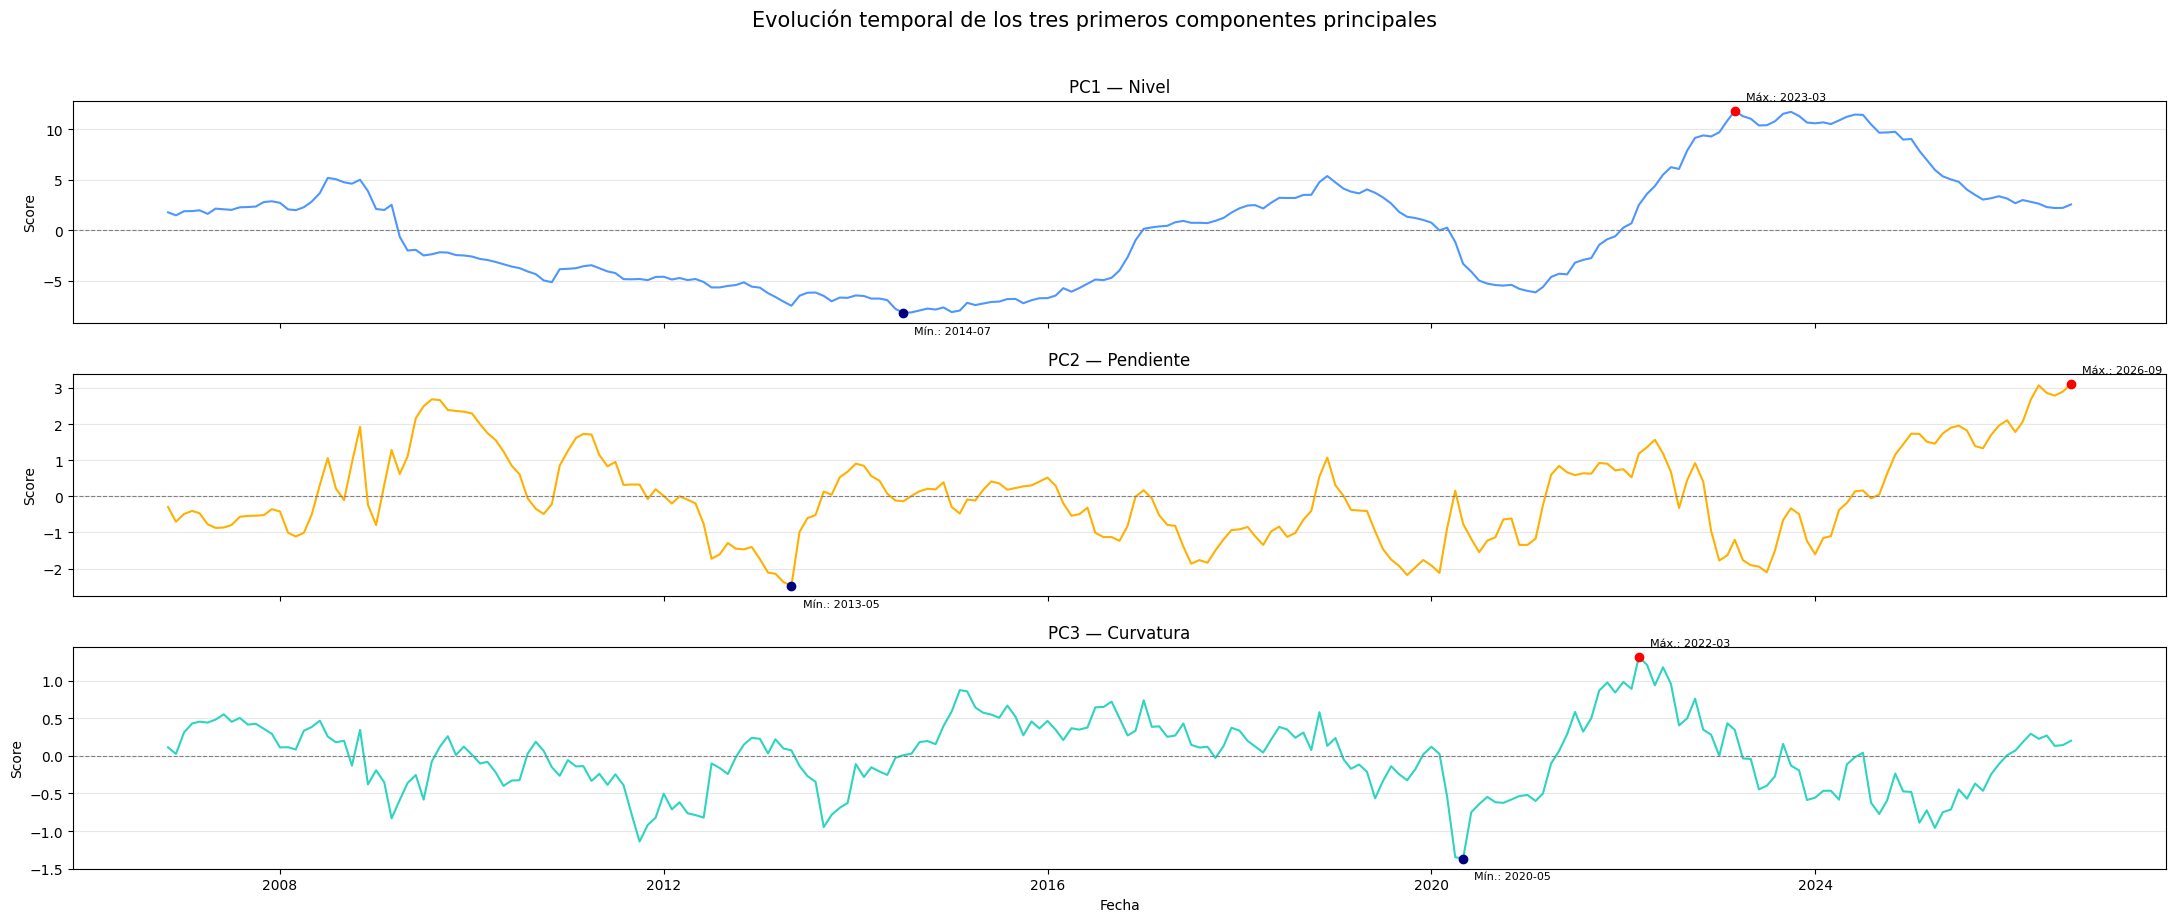

In [53]:
# Fechas correspondientes a las observaciones utilizadas en el PCA
fechas_pca = pd.to_datetime(matriz_pca_niveles.index)

# Scores de los tres primeros componentes
scores_pca = pd.DataFrame(
    scores_niveles[:, :3],
    index=fechas_pca,
    columns=["PC1", "PC2", "PC3"]
)

colores = {
    "PC1": "#4D96FF",
    "PC2": "#FFB000",
    "PC3": "#2DD4BF"
}

nombres = {
    "PC1": "PC1 — Nivel",
    "PC2": "PC2 — Pendiente",
    "PC3": "PC3 — Curvatura"
}

# Compatibilidad para ejecutar esta visualizaciÃ³n antes de la celda de construcciÃ³n.
import matplotlib.dates as mdates
horizontes = {3: '3 meses', 12: '12 meses'}
fecha_inicio_prueba = pd.Timestamp('2022-10-01')
fecha_fin_entrenamiento = pd.Timestamp('2022-09-01')
fecha_inicio = pd.Timestamp('2006-11-01')
_fechas = pd.DatetimeIndex(pd.to_datetime(tasas_mensuales_por_plazo.loc['2006-11-01':].index)).sort_values().unique()
ventanas = {}
for _h in horizontes:
    _ultimo = _fechas.max() - pd.DateOffset(months=_h)
    ventanas[_h] = {'entrenamiento': _fechas[_fechas <= fecha_fin_entrenamiento], 'prueba': _fechas[(_fechas >= fecha_inicio_prueba) & (_fechas <= _ultimo)]}

fig, axes = plt.subplots(
    3,
    1,
    figsize=(22, 9),
    sharex=True
)

for ax, componente in zip(
    axes,
    ["PC1", "PC2", "PC3"]
):
    serie = scores_pca[componente]

    ax.plot(
        serie.index,
        serie,
        color=colores[componente],
        linewidth=1.5
    )

    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(nombres[componente])
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)

    # Marcar máximo y mínimo del componente
    fecha_max = serie.idxmax()
    fecha_min = serie.idxmin()

    ax.scatter(
        fecha_max,
        serie.loc[fecha_max],
        color="red",
        zorder=3
    )

    ax.scatter(
        fecha_min,
        serie.loc[fecha_min],
        color="navy",
        zorder=3
    )

    ax.annotate(
        f"Máx.: {fecha_max.strftime('%Y-%m')}",
        xy=(fecha_max, serie.loc[fecha_max]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=8
    )

    ax.annotate(
        f"Mín.: {fecha_min.strftime('%Y-%m')}",
        xy=(fecha_min, serie.loc[fecha_min]),
        xytext=(8, -15),
        textcoords="offset points",
        fontsize=8
    )

axes[-1].set_xlabel("Fecha")

fig.suptitle(
    "Evolución temporal de los tres primeros componentes principales",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

**Lectura de la figura**

- **PC1 (nivel):** tramos largos y lentos, sin regresar a un nivel fijo por años — mínimo histórico en 2014-2015 (~3%), máximo en 2022-2023 (~11.25%), siguiendo casi exactamente el ciclo de política monetaria de Banxico. Esto confirma visualmente la alta persistencia/autocorrelación mencionada en la sección de niveles vs. cambios.
- **PC2 (pendiente):** se mueve con mayor frecuencia y, a diferencia de PC1, **regresa hacia cero repetidamente** en vez de alejarse por años — es menos persistente. Se observan picos abruptos y de corta duración en episodios de estrés de mercado (2008-2009, 2020), y el nivel más reciente (2025-2026) es el más alto de toda la serie.
- **PC3 (curvatura):** patrón similar a PC2 — oscilante, revirtiendose a la media, y sin tendencia secular. Alcanza su máximo histórico en 2022, y su mínimo durante la contracción de 2020.

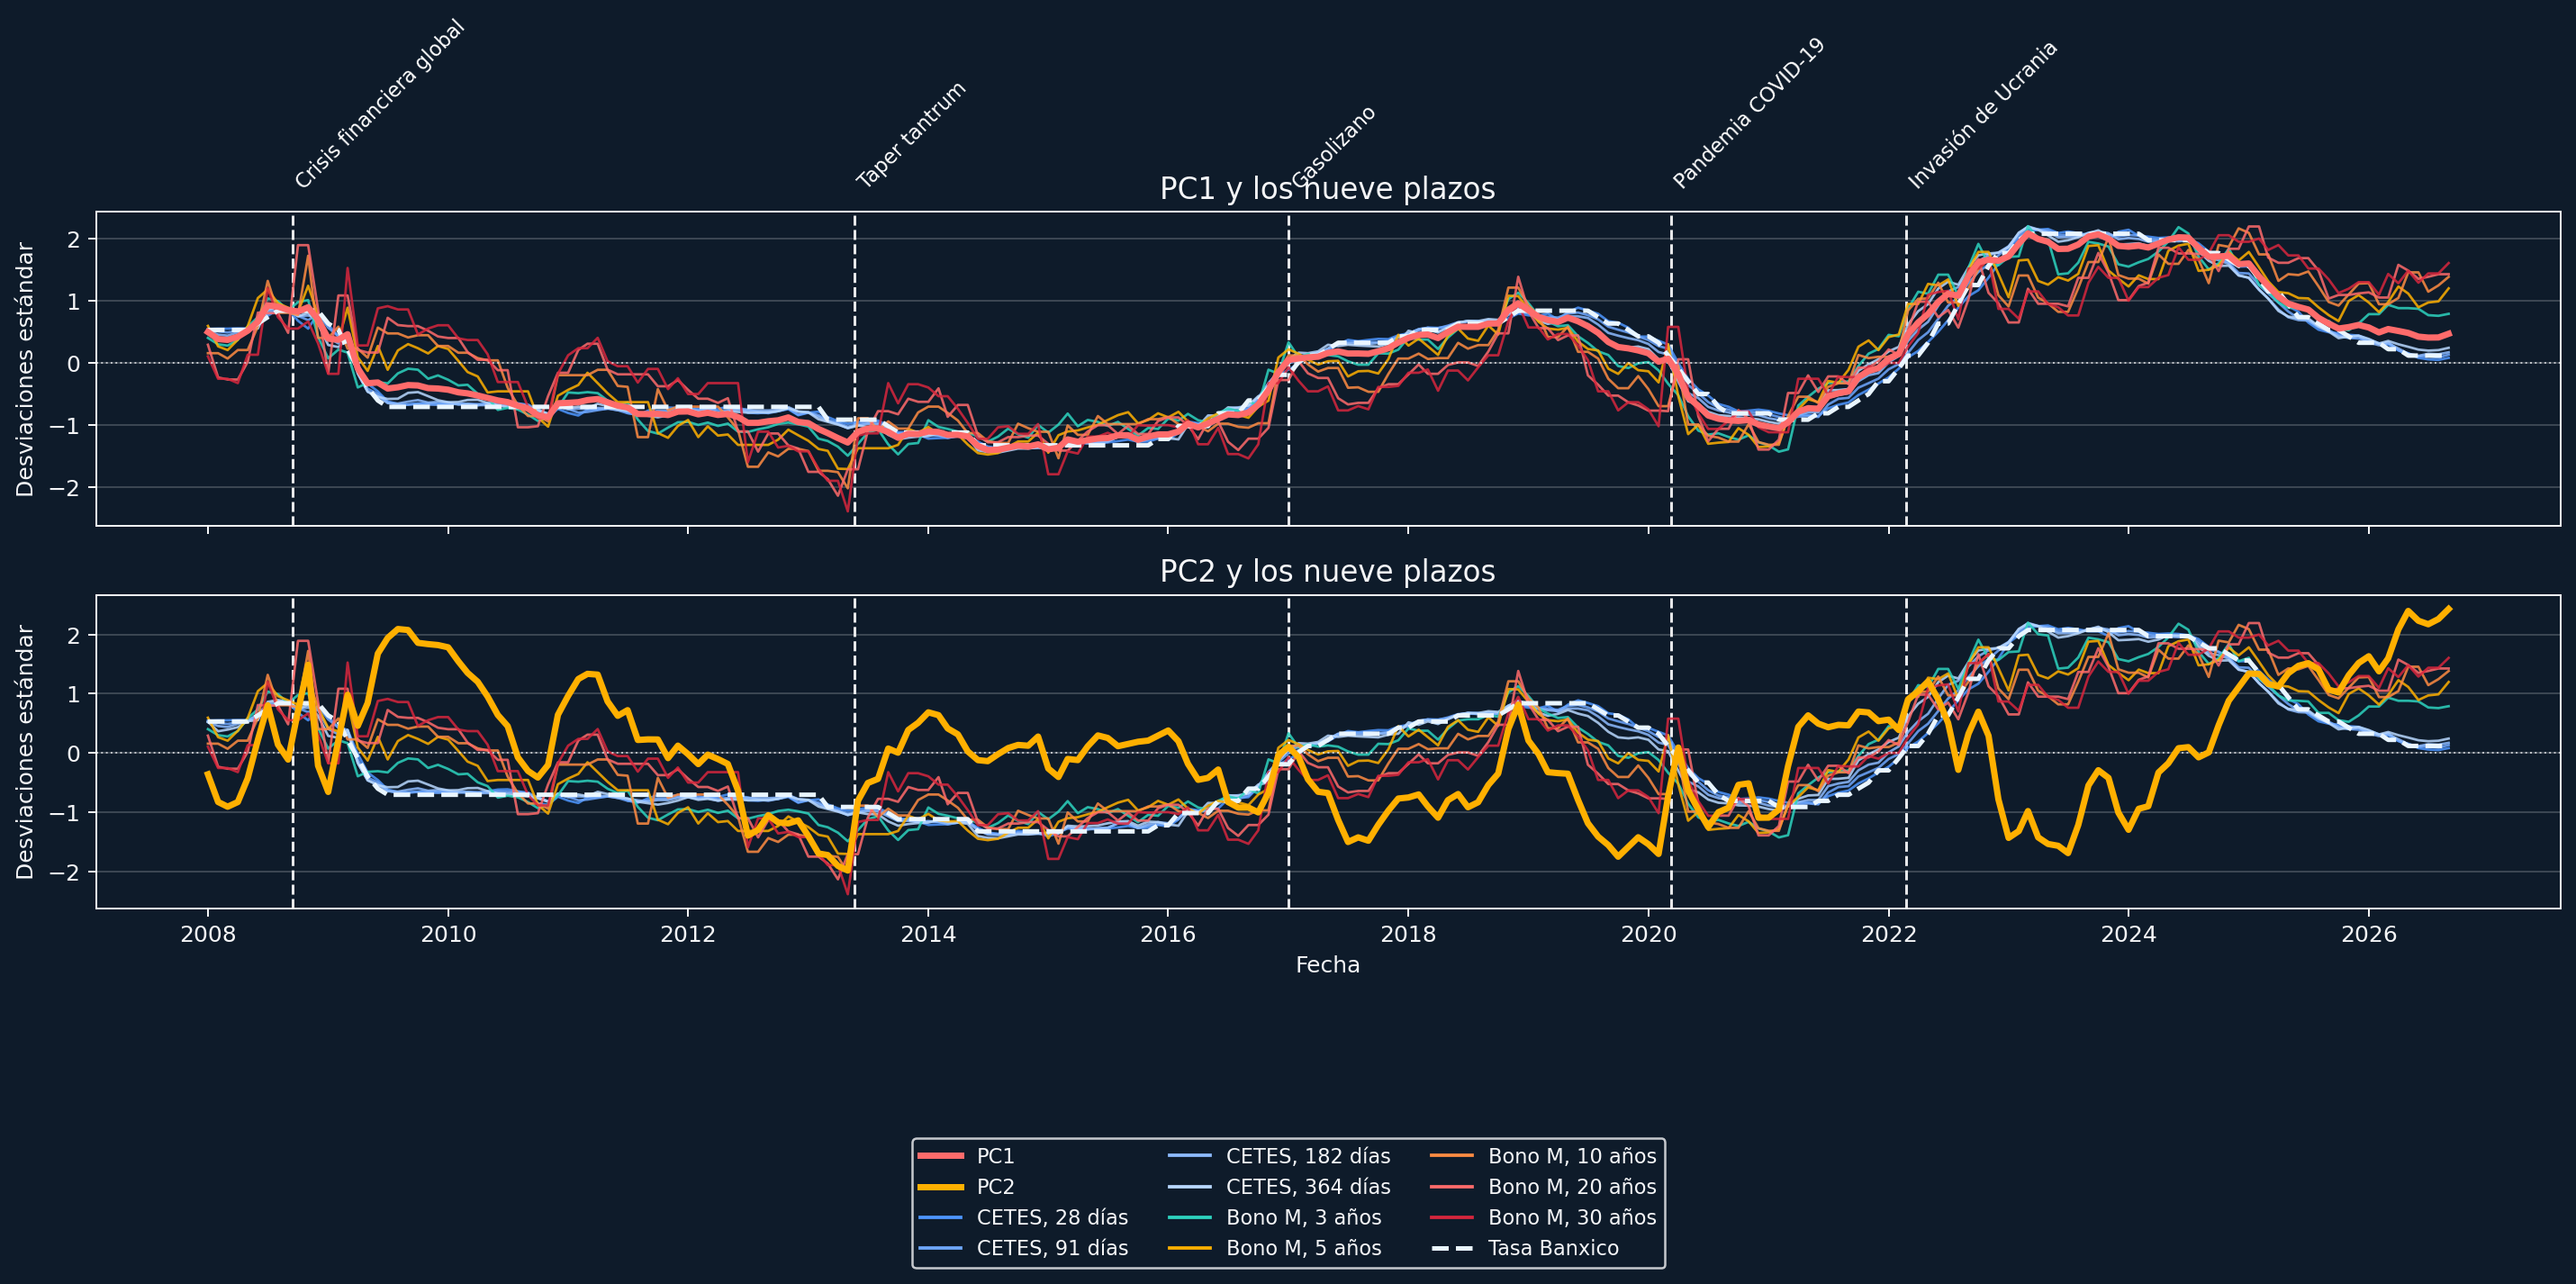

In [54]:
# ==================================================
from matplotlib.lines import Line2D
# 1. Plazos
# ==================================================

plazos = [
    "28d",
    "91d",
    "182d",
    "364d",
    "3a",
    "5a",
    "10a",
    "20a",
    "30a"
]

faltantes = [
    plazo
    for plazo in plazos
    if plazo not in matriz_pca_niveles.columns
]

if faltantes:
    raise KeyError(
        f"Faltan estos plazos: {faltantes}\n"
        f"Columnas disponibles: {matriz_pca_niveles.columns.tolist()}"
    )

# Etiquetas visibles
etiquetas_plazos = {
    "28d": "CETES, 28 días",
    "91d": "CETES, 91 días",
    "182d": "CETES, 182 días",
    "364d": "CETES, 364 días",
    "3a": "Bono M, 3 años",
    "5a": "Bono M, 5 años",
    "10a": "Bono M, 10 años",
    "20a": "Bono M, 20 años",
    "30a": "Bono M, 30 años"
}

# ==================================================
# 2. Alinear correctamente las observaciones del PCA
# ==================================================

pca_input = tasas_mensuales_forward_fill[plazos].dropna()

# Recalcular scores para garantizar que coincidan con estas nueve series.
modelo_grafica = PCA(n_components=2)
scores_grafica = modelo_grafica.fit_transform(pca_input)

fechas_pca = pd.to_datetime(pca_input.index)

componentes_pca = pd.DataFrame(
    scores_grafica[:, :2],
    index=fechas_pca,
    columns=["PC1", "PC2"]
)

# ==================================================
# 3. Preparar la tasa de Banxico
# ==================================================

if isinstance(tasa_banxico, pd.DataFrame):

    tasa_objetivo = tasa_banxico.copy()

    tasa_objetivo["Fecha"] = pd.to_datetime(
        tasa_objetivo["Fecha"]
    )

    tasa_objetivo["SF61745"] = pd.to_numeric(
        tasa_objetivo["SF61745"],
        errors="coerce"
    )

    tasa_objetivo = (
        tasa_objetivo
        .set_index("Fecha")["SF61745"]
        .sort_index()
        .resample("MS")
        .last()
        .rename("Tasa Banxico")
    )

else:

    tasa_objetivo = tasa_banxico.copy()
    tasa_objetivo.index = pd.to_datetime(
        tasa_objetivo.index
    )

    tasa_objetivo = (
        pd.to_numeric(
            tasa_objetivo,
            errors="coerce"
        )
        .sort_index()
        .rename("Tasa Banxico")
    )

# ==================================================
# 4. Combinar y estandarizar
# ==================================================

comparacion = pd.concat(
    [
        componentes_pca,
        pca_input,
        tasa_objetivo
    ],
    axis=1
).dropna()

comparacion_estandarizada = (
    comparacion - comparacion.mean()
) / comparacion.std()

# ==================================================
# 5. Eventos relevantes
# ==================================================

eventos = {
    "Crisis financiera global": pd.Timestamp("2008-09-15"),
    "Taper tantrum": pd.Timestamp("2013-05-22"),
    "Gasolizano": pd.Timestamp("2017-01-01"),
    "Pandemia COVID-19": pd.Timestamp("2020-03-11"),
    "Invasión de Ucrania": pd.Timestamp("2022-02-24")
}

# ==================================================
# 6. Colores
# ==================================================

colores_pca = {
    "PC1": "#FF6B6B",
    "PC2": "#FFB000"
}

colores_plazos = {
    "28d": "#4D96FF",
    "91d": "#6FA8FF",
    "182d": "#8DBBFF",
    "364d": "#B8D8FF",
    "3a": "#2DD4BF",
    "5a": "#FFB000",
    "10a": "#FF8C42",
    "20a": "#FF6B6B",
    "30a": "#D7263D"
}

color_banxico = "#E9F5FF"
color_fondo = "#0E1B2A"
color_texto = "#F4F5F7"
color_eventos = "#FFFFFF"

# ==================================================
# 7. Crear figura en alta resolución
# ==================================================

plt.close("all")

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 9),
    dpi=180,
    sharex=True
)

# ==================================================
# 8. Graficar PC1 y PC2
# ==================================================

for numero, (ax, componente) in enumerate(
    zip(axes, ["PC1", "PC2"])
):

    ax.set_facecolor(color_fondo)

    # Componente principal
    ax.plot(
        comparacion_estandarizada.index,
        comparacion_estandarizada[componente],
        color=colores_pca[componente],
        linewidth=2.8,
        label=componente,
        zorder=5
    )

    # Los nueve plazos, incluidos los largos
    for plazo in plazos:
        ax.plot(
            comparacion_estandarizada.index,
            comparacion_estandarizada[plazo],
            color=colores_plazos[plazo],
            linewidth=1.1,
            alpha=0.85,
            label=(
                etiquetas_plazos[plazo]
                if numero == 0
                else "_nolegend_"
            ),
            zorder=2
        )

    # Tasa objetivo de Banxico
    ax.plot(
        comparacion_estandarizada.index,
        comparacion_estandarizada["Tasa Banxico"],
        color=color_banxico,
        linestyle="--",
        linewidth=2,
        label=(
            "Tasa Banxico"
            if numero == 0
            else "_nolegend_"
        ),
        zorder=4
    )

    # Eventos en blanco
    for nombre, fecha in eventos.items():
        ax.axvline(
            fecha,
            color=color_eventos,
            linestyle="--",
            linewidth=1.2,
            alpha=0.9,
            zorder=1
        )

    ax.axhline(
        0,
        color=color_texto,
        linestyle=":",
        linewidth=0.8,
        alpha=0.7
    )

    ax.set_title(
        f"{componente} y los nueve plazos",
        color=color_texto,
        fontsize=13
    )

    ax.set_ylabel(
        "Desviaciones estándar",
        color=color_texto
    )

    ax.tick_params(
        axis="both",
        colors=color_texto
    )

    ax.grid(
        axis="y",
        color=color_texto,
        alpha=0.2
    )

    for borde in ax.spines.values():
        borde.set_color(color_texto)

# ==================================================
# 9. Etiquetas de eventos
# ==================================================

for nombre, fecha in eventos.items():
    axes[0].text(
        fecha,
        1.06,
        nombre,
        rotation=45,
        transform=axes[0].get_xaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=9,
        color=color_eventos,
        clip_on=False
    )

# ==================================================
# 10. Leyenda única
# ==================================================

handles_pca = [
    Line2D(
        [0],
        [0],
        color=colores_pca[componente],
        linewidth=2.8,
        label=componente
    )
    for componente in ["PC1", "PC2"]
]

handles_plazos = [
    Line2D(
        [0],
        [0],
        color=colores_plazos[plazo],
        linewidth=1.5,
        label=etiquetas_plazos[plazo]
    )
    for plazo in plazos
]

handle_banxico = Line2D(
    [0],
    [0],
    color=color_banxico,
    linestyle="--",
    linewidth=2,
    label="Tasa Banxico"
)

handles_leyenda = (
    handles_pca
    + handles_plazos
    + [handle_banxico]
)

fig.legend(
    handles=handles_leyenda,
    labels=[
        handle.get_label()
        for handle in handles_leyenda
    ],
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.01),
    facecolor=color_fondo,
    edgecolor=color_texto,
    labelcolor=color_texto,
    fontsize=9
)

# ==================================================
# 11. Formato y exportación en alta resolución
# ==================================================

axes[-1].set_xlabel(
    "Fecha",
    color=color_texto
)

fig.patch.set_facecolor(color_fondo)

plt.tight_layout(
    rect=[0, 0.18, 1, 0.88]
)
output_dir = Path("outputs/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "pc1_pc2_plazos_eventos.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

**Lectura de la figura**

- Esta gráfica muestra visualmente lo que las cargas y la varianza explicada ya habían demostrado numéricamente: los nueve plazos no se mueven de forma independiente, sino que comparten un patrón común que PCA logra resumir en pocos factores. PC1 (nivel) se superpone casi exactamente con el conjunto de los nueve plazos a lo largo de los 20 años — validado visualmente que un solo componente captura la mayor parte del movimiento conjunto de la curva.
- PC2 (pendiente), en cambio, se separa con claridad del resto en varios tramos — evidencia de que, aunque el nivel domina, se necesita un segundo factor para capturar cómo cambia la *forma* de la curva (no solo su altura) en distintos periodos. PC2 es más sensible a los movimientos de los plazos largos que de los cortos: sus cargas son mayores en magnitud en el extremo largo (0.47 en 30 años) que en el corto (−0.29 en 28 días) — consistente con su interpretación como factor de pendiente.
- Los periodos de mayor estrés de mercado (2008, 2020, 2022) coinciden con los movimientos más marcados tanto en nivel como en pendiente, lo cual es consistente con el resto del análisis, aunque no es el punto central de esta figura.

### Cierre del Módulo 3

Los resultados obtenidos aqui sugieren que sí existe una estructura común en los rendimientos de los distintos plazos. En niveles, los tres primeros componentes —nivel, pendiente y curvatura— explican 99.38% de la variación y resumen casi por completo el comportamiento conjunto de la curva. Con la estructura identificada, el siguiente módulo pregunta si esa información puede convertirse en pronósticos fuera de muestra.


## Módulo 4 — Evaluación de pronósticos


**¿Podemos pronosticar la curva a 3 y 12 meses?**


### Paso 1 — Definir el problema de pronóstico

La pregunta busca determinar si la curva de rendimientos, compuesta por nueve plazos de 28 días a 30 años, puede pronosticarse a uno y cuatro trimestres, es decir, a 3 y 12 meses, dado que la serie es mensual. Para responderla se construyen tres benchmarks, métodos simples de referencia que cualquier modelo debe superar:

- **Random walk:** el pronóstico para cualquier horizonte es el último valor observado.
- **Promedio móvil de 12 meses:** el pronóstico es el promedio de los últimos doce valores.
- **Media histórica:** el pronóstico es el promedio de todos los valores previos.

Se evalúa cada benchmark con RMSE y MAE sobre los mismos orígenes y horizontes, y el de menor error se usa como referencia para comparar después con un método más elaborado.

La evaluación fuera de muestra se realiza con un esquema de ventana creciente: a partir de un periodo inicial de entrenamiento, se genera un pronóstico para cada horizonte en cada mes disponible, y se compara contra el valor real una vez observado, repitiendo el proceso mes a mes. Esto produce una secuencia de errores de pronóstico —no un único par pronóstico-vs-real— siguiendo la práctica estándar de evaluación de pronósticos (Diebold y Mariano, 2002). El error se resume mediante RMSE y MAE, calculados por plazo y por horizonte, y comparados contra el error del no-cambio para determinar si existe una mejora real.


### Paso 2 — Construir las muestras de entrenamiento y prueba

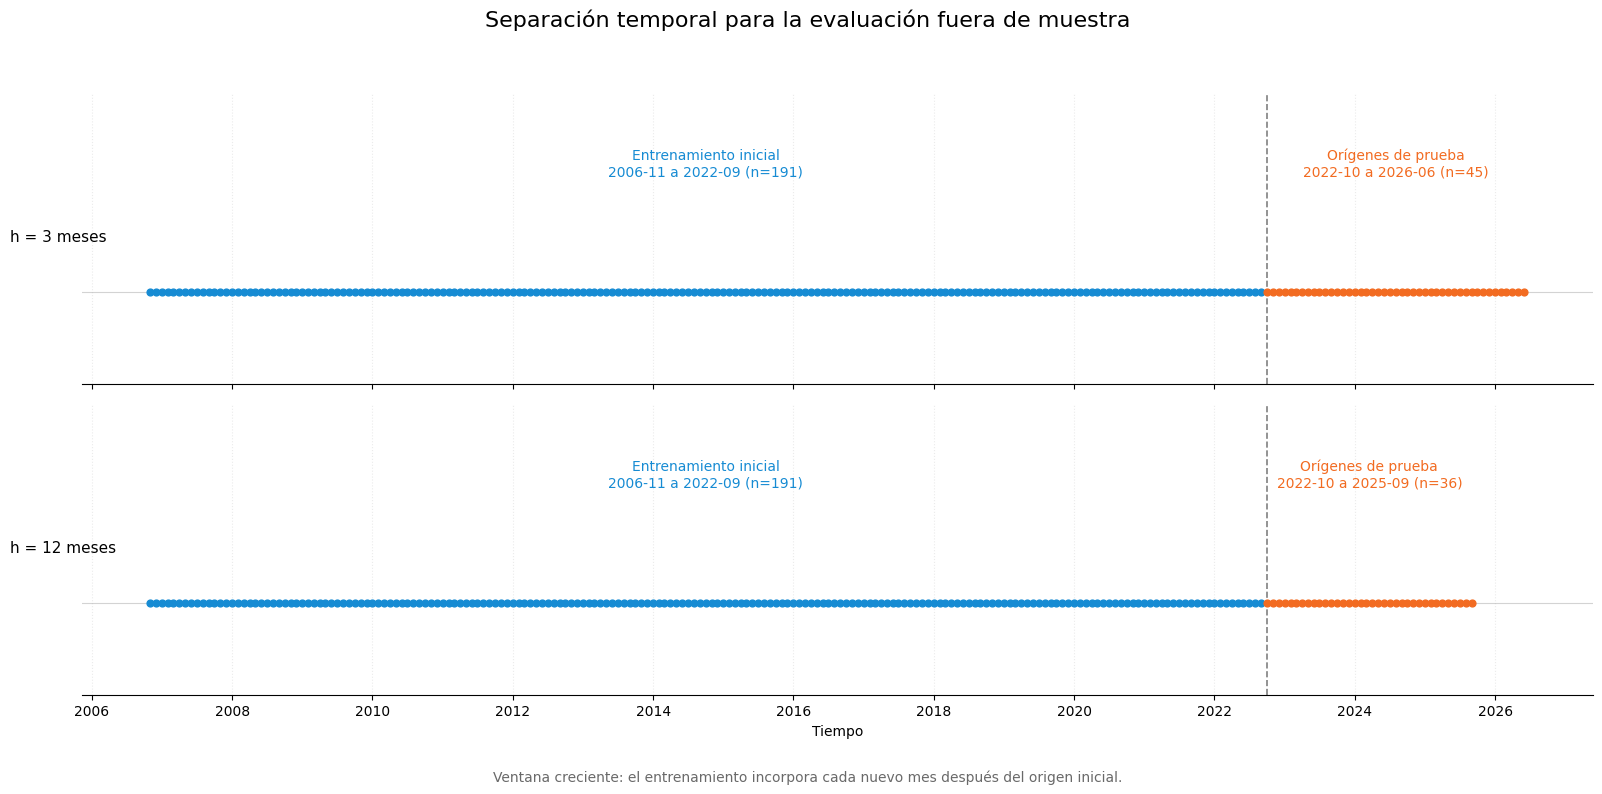

In [55]:

# ============================================================
# 3. Graficar la separación temporal
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 8),
    sharex=True
)

colores = {
    "entrenamiento": "#168BD3",
    "prueba": "#F26B21"
}

for ax, (horizonte, etiqueta) in zip(
    axes,
    horizontes.items()
):

    fechas_entrenamiento = ventanas[horizonte]["entrenamiento"]
    fechas_origenes_prueba = ventanas[horizonte]["prueba"]

    # Línea de separación entre entrenamiento y prueba
    ax.axvline(
        fecha_inicio_prueba,
        color="gray",
        linestyle="--",
        linewidth=1.2,
        zorder=1
    )

    # Observaciones de entrenamiento
    ax.scatter(
        fechas_entrenamiento,
        [0] * len(fechas_entrenamiento),
        color=colores["entrenamiento"],
        s=24,
        label="Entrenamiento inicial",
        zorder=3
    )

    # Orígenes de evaluación fuera de muestra
    ax.scatter(
        fechas_origenes_prueba,
        [0] * len(fechas_origenes_prueba),
        color=colores["prueba"],
        s=24,
        label="Orígenes de prueba",
        zorder=4
    )

    # Etiqueta del horizonte
    ax.text(
        fecha_inicio - pd.DateOffset(months=24),
        0.18,
        f"h = {horizonte} meses",
        fontsize=11,
        ha="left",
        va="center"
    )

    # Etiqueta del entrenamiento
    ax.text(
        fecha_inicio
        + (fecha_fin_entrenamiento - fecha_inicio) / 2,
        0.42,
        (
            "Entrenamiento inicial\n"
            f"{fechas_entrenamiento.min().strftime('%Y-%m')}"
            " a "
            f"{fechas_entrenamiento.max().strftime('%Y-%m')}"
            f" (n={len(fechas_entrenamiento)})"
        ),
        color=colores["entrenamiento"],
        fontsize=10,
        ha="center",
        va="center"
    )

    # Etiqueta de los orígenes de prueba
    ax.text(
        fechas_origenes_prueba.min()
        + (
            fechas_origenes_prueba.max()
            - fechas_origenes_prueba.min()
        ) / 2,
        0.42,
        (
            "Orígenes de prueba\n"
            f"{fechas_origenes_prueba.min().strftime('%Y-%m')}"
            " a "
            f"{fechas_origenes_prueba.max().strftime('%Y-%m')}"
            f" (n={len(fechas_origenes_prueba)})"
        ),
        color=colores["prueba"],
        fontsize=10,
        ha="center",
        va="center"
    )

    # Línea horizontal de referencia
    ax.axhline(
        0,
        color="lightgray",
        linewidth=0.8,
        zorder=0
    )

    ax.set_ylim(-0.30, 0.65)
    ax.set_yticks([])

    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.25
    )

# ============================================================
# 4. Formato final
# ============================================================

axes[-1].xaxis.set_major_locator(
    mdates.YearLocator(2)
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

axes[-1].set_xlabel("Tiempo")

fig.suptitle(
    "Separación temporal para la evaluación fuera de muestra",
    fontsize=16,
    y=0.98
)

fig.text(
    0.5,
    0.015,
    "Ventana creciente: el entrenamiento incorpora cada nuevo mes "
    "después del origen inicial.",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

# ============================================================
# 5. Guardar la figura
# ============================================================

output_dir = "outputs/figures"

plt.savefig(
    f"{output_dir}/separacion_temporal_pronosticos.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    f"{output_dir}/separacion_temporal_pronosticos.pdf",
    bbox_inches="tight"
)

plt.show()

In [56]:
# ============================================================
# Paso 2. Muestra de entrenamiento y prueba
# ============================================================

# Se aplica forward-fill conservando octubre como antecedente causal.
# Después se recorta desde noviembre: el valor del bono a 30 años
# de octubre puede completar noviembre-enero sin usar información futura.
datos_pronostico = (
    tasas_mensuales_por_plazo
    .ffill()
    .loc["2006-11-01":]
    .copy()
)

# Asegurar que el índice tenga formato de fecha para poder
# filtrar y hacer operaciones temporales.
datos_pronostico.index = pd.to_datetime(
    datos_pronostico.index
)

# Crear la lista ordenada y sin fechas repetidas que servirá
# para definir los orígenes de pronóstico.
fechas_muestra = pd.DatetimeIndex(
    datos_pronostico.index
).sort_values().unique()

# Fijar el periodo inicial de entrenamiento y el inicio de la prueba.
fecha_fin_entrenamiento = pd.Timestamp("2022-09-01")
fecha_inicio_prueba = pd.Timestamp("2022-10-01")

# Obtener la última fecha disponible en la muestra.
fecha_final_muestra = fechas_muestra.max()

# Definir horizontes a 3 y 12 meses
horizontes = [3, 12]

# Aquí se guardarán las muestras de entrenamiento, orígenes
# y fechas objetivo para cada horizonte.
muestras_pronostico = {}

# Construir por separado las muestras de cada horizonte.
for horizonte in horizontes:

    # El último origen debe estar lo bastante antes del final
    # para que exista una observación objetivo para este horizonte.
    fecha_ultimo_origen = (
        fecha_final_muestra
        - pd.DateOffset(months=horizonte)
    )

    # Seleccionar el entrenamiento inicial hasta septiembre de 2022.
    train = datos_pronostico.loc[
        datos_pronostico.index <= fecha_fin_entrenamiento
    ].copy()

    # Seleccionar como orígenes de prueba las fechas desde octubre de 2022
    # hasta el último origen que permite observar el objetivo.
    origenes_prueba = fechas_muestra[
        (fechas_muestra >= fecha_inicio_prueba)
        & (fechas_muestra <= fecha_ultimo_origen)
    ]

    # Para cada origen, calcular la fecha situada horizonte meses adelante.
    fechas_objetivo = (
        origenes_prueba
        + pd.DateOffset(months=horizonte)
    )

    # Extraer de los datos las observaciones disponibles en las fechas
    # objetivo. Estas son las tasas reales contra las que se evaluarán
    # los pronósticos.
    test = datos_pronostico.loc[
        datos_pronostico.index.isin(fechas_objetivo)
    ].copy()

    # Guardar todos los elementos de la muestra bajo la clave del horizonte.
    muestras_pronostico[horizonte] = {
        "train_inicial": train,
        "origenes_prueba": origenes_prueba,
        "fechas_objetivo": fechas_objetivo,
        "test": test
    }

    # Mostrar un resumen del diseño de evaluación para este horizonte.
    print(f"\nh = {horizonte} meses")

    # Reportar el periodo y número de observaciones del entrenamiento.
    print(
        "Entrenamiento:",
        train.index.min().strftime("%Y-%m"),
        "a",
        train.index.max().strftime("%Y-%m"),
        f"(n={len(train)})"
    )

    # Reportar el rango y número de fechas desde las que se generan
    # pronósticos fuera de muestra.
    print(
        "Orígenes de prueba:",
        origenes_prueba.min().strftime("%Y-%m"),
        "a",
        origenes_prueba.max().strftime("%Y-%m"),
        f"(n={len(origenes_prueba)})"
    )

    # Reportar el rango y número de fechas objetivo de los pronósticos.
    print(
        "Fechas objetivo:",
        fechas_objetivo.min().strftime("%Y-%m"),
        "a",
        fechas_objetivo.max().strftime("%Y-%m"),
        f"(n={len(fechas_objetivo)})"
    )

    # Reportar cuántas observaciones reales quedaron disponibles
    # para comparar con los pronósticos.
    print(
        "Observaciones disponibles para evaluar:",
        len(test)
    )


h = 3 meses
Entrenamiento: 2006-11 a 2022-09 (n=191)
Orígenes de prueba: 2022-10 a 2026-06 (n=45)
Fechas objetivo: 2023-01 a 2026-09 (n=45)
Observaciones disponibles para evaluar: 45

h = 12 meses
Entrenamiento: 2006-11 a 2022-09 (n=191)
Orígenes de prueba: 2022-10 a 2025-09 (n=36)
Fechas objetivo: 2023-10 a 2026-09 (n=36)
Observaciones disponibles para evaluar: 36


### Paso 3 — Definir los pronósticos de referencia

Se establecerán uno o más benchmarks sencillos —por ejemplo, persistencia o promedio histórico— para saber si un modelo más elaborado aporta valor.

Se comparan tres referencias: persistencia, promedio móvil de 12 meses y media histórica. La persistencia representa el supuesto de no cambio y sirve como benchmark principal para los modelos multivariados.


In [57]:
# ============================================================
# Paso 3. Pronósticos de referencia (benchmarks)
# ============================================================

import pandas as pd

# ============================================================
# 1. Plazos utilizados
# ============================================================

plazos = [
    "28d", "91d", "182d", "364d",
    "3a", "5a", "10a", "20a", "30a"
]

# ============================================================
# 2. Base para pronóstico
# ============================================================

# Se aplica forward-fill antes del recorte temporal para conservar
# observaciones previas disponibles sin usar información futura.
base_pronostico = (
    tasas_mensuales_por_plazo[plazos]
    .ffill()
    .loc["2006-11-01":]
    .dropna()
)

base_pronostico.index = pd.to_datetime(
    base_pronostico.index
)

base_pronostico = base_pronostico.sort_index()

# ============================================================
# 3. Parámetros de evaluación
# ============================================================

fecha_inicio_prueba = pd.Timestamp("2022-10-01")
horizontes = [3, 12]

# Diccionarios para guardar resultados
pronosticos_benchmark = {}
observados_benchmark = {}

# ============================================================
# 4. Construcción de los benchmarks
# ============================================================

for horizonte in horizontes:

    # El último origen debe dejar disponibles h meses
    # para evaluar el pronóstico.
    ultima_fecha_origen = (
        base_pronostico.index.max()
        - pd.DateOffset(months=horizonte)
    )

    # Orígenes disponibles para generar pronósticos
    origenes = base_pronostico.index[
        (base_pronostico.index >= fecha_inicio_prueba)
        & (base_pronostico.index <= ultima_fecha_origen)
    ]

    # Tablas de resultados:
    # cada fila representa un origen de pronóstico
    persistencia = pd.DataFrame(
        index=origenes,
        columns=plazos,
        dtype=float
    )

    promedio_historico = pd.DataFrame(
        index=origenes,
        columns=plazos,
        dtype=float
    )

    promedio_movil_12 = pd.DataFrame(
        index=origenes,
        columns=plazos,
        dtype=float
    )

    observados = pd.DataFrame(
        index=origenes,
        columns=plazos,
        dtype=float
    )

    # --------------------------------------------------------
    # Generar pronósticos para cada origen
    # --------------------------------------------------------

    for origen in origenes:

        # Fecha que se desea pronosticar
        fecha_objetivo = (
            origen
            + pd.DateOffset(months=horizonte)
        )

        # Valor observado real en la fecha objetivo
        observados.loc[origen, plazos] = (
            base_pronostico.loc[
                fecha_objetivo,
                plazos
            ]
        )

        # Información disponible únicamente hasta el origen
        informacion_hasta_origen = (
            base_pronostico.loc[:origen, plazos]
        )

        # ----------------------------------------------------
        # Benchmark 1: persistencia
        # ----------------------------------------------------
        # El último valor observado se mantiene constante.
        persistencia.loc[origen, plazos] = (
            base_pronostico.loc[origen, plazos]
        )

        # ----------------------------------------------------
        # Benchmark 2: promedio histórico acumulado
        # ----------------------------------------------------
        promedio_historico.loc[origen, plazos] = (
            informacion_hasta_origen.mean()
        )

        # ----------------------------------------------------
        # Benchmark 3: promedio móvil de 12 meses
        # ----------------------------------------------------
        promedio_movil_12.loc[origen, plazos] = (
            informacion_hasta_origen
            .tail(12)
            .mean()
        )

    # Guardar pronósticos y valores observados
    pronosticos_benchmark[horizonte] = {
        "Persistencia": persistencia,
        "Promedio histórico": promedio_historico,
        "Promedio móvil 12 meses": promedio_movil_12
    }

    observados_benchmark[horizonte] = observados

    # ========================================================
    # 5. Validación de fechas y tamaños
    # ========================================================

    primer_objetivo = (
        origenes.min()
        + pd.DateOffset(months=horizonte)
    )

    ultimo_objetivo = (
        origenes.max()
        + pd.DateOffset(months=horizonte)
    )

    print(f"\nh = {horizonte} meses")

    print(
        "Orígenes utilizados:",
        len(origenes)
    )

    print(
        "Primer origen:",
        origenes.min().strftime("%Y-%m")
    )

    print(
        "Último origen:",
        origenes.max().strftime("%Y-%m")
    )

    print(
        "Primer objetivo:",
        primer_objetivo.strftime("%Y-%m")
    )

    print(
        "Último objetivo:",
        ultimo_objetivo.strftime("%Y-%m")
    )

    print(
        "Observaciones disponibles para evaluar:",
        len(observados)
    )

# ============================================================
# 6. Revisar una muestra de los resultados
# ============================================================

print("\nEjemplo de pronósticos para h = 3 meses:")
display(
    pronosticos_benchmark[3]["Persistencia"]
    .head()
    .round(3)
)

print("\nValores observados correspondientes:")
display(
    observados_benchmark[3]
    .head()
    .round(3)
)

print("\nEjemplo de pronósticos para h = 12 meses:")
display(
    pronosticos_benchmark[12]["Persistencia"]
    .head()
    .round(3)
)

print("\nValores observados correspondientes para h = 12:")
display(
    observados_benchmark[12]
    .head()
    .round(3)
)


h = 3 meses
Orígenes utilizados: 45
Primer origen: 2022-10
Último origen: 2026-06
Primer objetivo: 2023-01
Último objetivo: 2026-09
Observaciones disponibles para evaluar: 45

h = 12 meses
Orígenes utilizados: 36
Primer origen: 2022-10
Último origen: 2025-09
Primer objetivo: 2023-10
Último objetivo: 2026-09
Observaciones disponibles para evaluar: 36

Ejemplo de pronósticos para h = 3 meses:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,8.93,9.87,10.43,10.77,10.33,9.98,9.52,9.93,9.77
2022-11-01,9.42,10.17,10.68,10.84,9.73,9.98,9.75,9.28,9.94
2022-12-01,9.96,10.53,10.78,10.87,9.69,9.39,8.94,9.08,9.03
2023-01-01,10.61,10.88,11.03,11.09,9.94,8.76,8.69,8.71,9.03
2023-02-01,10.92,11.29,11.54,11.66,9.96,9.75,9.38,8.71,8.85



Valores observados correspondientes:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,10.61,10.88,11.03,11.09,9.94,8.76,8.69,8.71,9.03
2022-11-01,10.92,11.29,11.54,11.66,9.96,9.75,9.38,8.71,8.85
2022-12-01,11.23,11.59,11.82,11.88,10.86,9.77,9.38,9.36,9.35
2023-01-01,11.29,11.55,11.70,11.77,10.50,9.20,8.89,9.07,9.35
2023-02-01,11.32,11.51,11.58,11.55,10.46,9.10,8.76,9.07,9.12



Ejemplo de pronósticos para h = 12 meses:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,8.93,9.87,10.43,10.77,10.33,9.98,9.52,9.93,9.77
2022-11-01,9.42,10.17,10.68,10.84,9.73,9.98,9.75,9.28,9.94
2022-12-01,9.96,10.53,10.78,10.87,9.69,9.39,8.94,9.08,9.03
2023-01-01,10.61,10.88,11.03,11.09,9.94,8.76,8.69,8.71,9.03
2023-02-01,10.92,11.29,11.54,11.66,9.96,9.75,9.38,8.71,8.85



Valores observados correspondientes para h = 12:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,11.08,11.38,11.62,11.75,10.34,10.16,9.68,10.05,9.80
2022-11-01,10.89,11.36,11.55,11.52,10.25,9.48,10.23,9.67,9.60
2022-12-01,11.21,11.28,11.31,11.19,9.72,9.26,9.39,9.14,9.60
2023-01-01,11.29,11.34,11.36,11.21,9.65,9.05,9.31,9.14,9.18
2023-02-01,11.05,11.31,11.32,11.24,9.78,9.35,9.31,9.41,9.43


### Paso 4 — Evaluar el desempeño

Se calcularán RMSE y MAE por plazo y por modelo. RMSE penaliza más los errores grandes; MAE representa el error absoluto promedio en la unidad de la tasa.

**Validación:** comparar cada modelo contra el benchmark y revisar si los resultados son consistentes entre plazos.


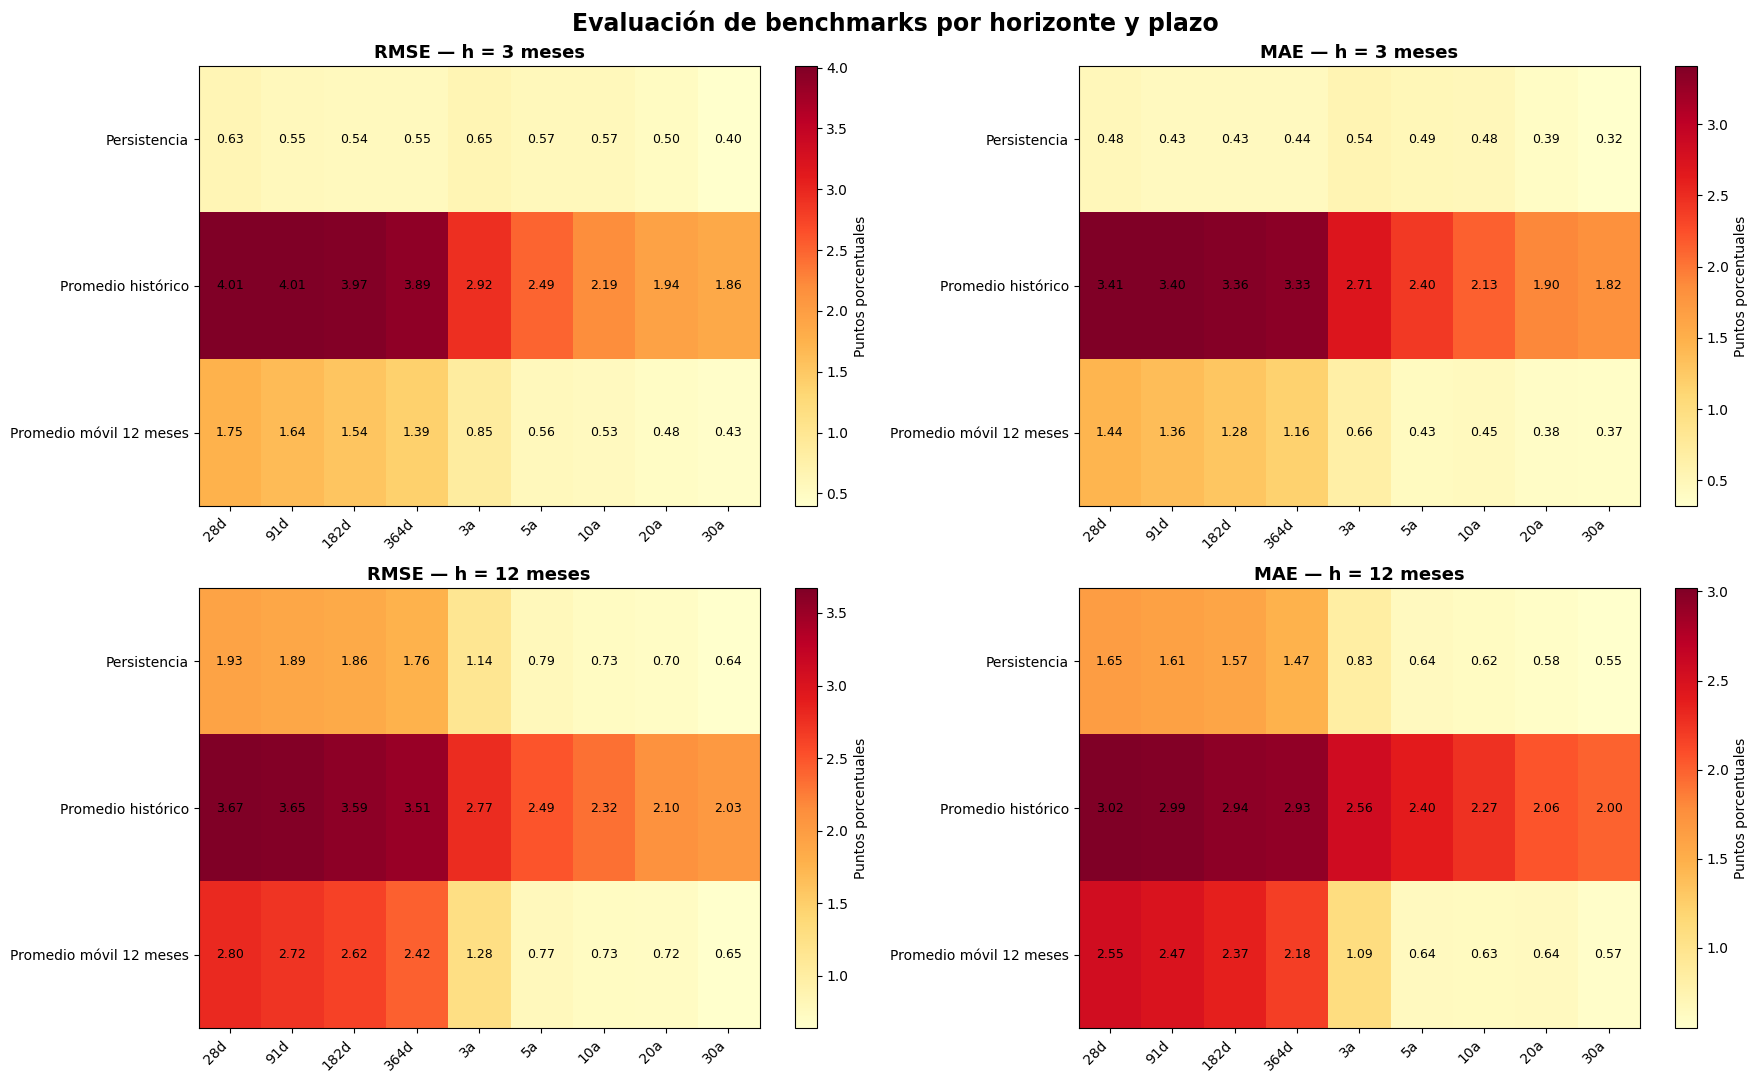

In [58]:
# Importar las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Evaluación de los tres benchmarks por plazo y horizonte
# ============================================================

# Aquí se guardarán las métricas calculadas para cada combinación
# de horizonte, modelo y plazo.
resultados_evaluacion = []

# Recorrer cada horizonte de pronóstico, por ejemplo 3 y 12 meses.
for _h in horizontes:

    # Obtener las tasas reales correspondientes a las fechas objetivo
    # de este horizonte.
    _obs = observados_benchmark[_h]

    # Recorrer los modelos benchmark y sus pronósticos.
    for _modelo, _pron in pronosticos_benchmark[_h].items():

        # Calcular las métricas por separado para cada plazo.
        for _plazo in plazos:

            # Restar el pronóstico a la tasa observada y excluir
            # fechas en las que no haya un valor para comparar.
            _errores = (_obs[_plazo] - _pron[_plazo]).dropna()

            # Guardar RMSE, MAE y cantidad de observaciones comparables.
            resultados_evaluacion.append({
                "horizonte_meses": _h,
                "modelo": _modelo,
                "plazo": _plazo,
                "RMSE": np.sqrt(np.mean(_errores ** 2)),
                "MAE": np.mean(np.abs(_errores)),
                "observaciones": len(_errores)
            })

# Convertir la lista de resultados en una tabla para consultarla
# y usarla en las gráficas.
resultados_evaluacion = pd.DataFrame(resultados_evaluacion)

# ============================================================
# Orden de modelos y plazos en la figura
# ============================================================

# Fijar el orden de los modelos para que sea igual en ambos mapas.
orden_modelos = [
    "Persistencia",
    "Promedio histórico",
    "Promedio móvil 12 meses"
]

# Fijar el orden de los plazos de corto a largo.
orden_plazos = [
    "28d", "91d", "182d", "364d",
    "3a", "5a", "10a", "20a", "30a"
]

# ============================================================
# Función para graficar una métrica de error
# ============================================================

def graficar_mapa_error(resultados, horizonte, metrica, ax):
    """Dibuja la métrica elegida por modelo y plazo para un horizonte."""

    # Filtrar los resultados para el horizonte solicitado y organizarlos
    # en una tabla: filas = modelos, columnas = plazos.
    tabla = (
        resultados[
            resultados["horizonte_meses"] == horizonte
        ]
        .pivot(
            index="modelo",
            columns="plazo",
            values=metrica
        )
        .reindex(
            index=orden_modelos,
            columns=orden_plazos
        )
    )

    # Dibujar la tabla como mapa de calor.
    imagen = ax.imshow(
        tabla.values,
        cmap="YlOrRd",
        aspect="auto"
    )

    # Añadir título según la métrica y el horizonte.
    ax.set_title(
        f"{metrica} — h = {horizonte} meses",
        fontsize=13,
        fontweight="bold"
    )

    # Etiquetar el eje horizontal con los plazos.
    ax.set_xticks(range(len(orden_plazos)))
    ax.set_xticklabels(
        orden_plazos,
        rotation=45,
        ha="right"
    )

    # Etiquetar el eje vertical con los modelos.
    ax.set_yticks(range(len(orden_modelos)))
    ax.set_yticklabels(orden_modelos)

    # Escribir el valor de la métrica dentro de cada celda.
    for fila in range(tabla.shape[0]):
        for columna in range(tabla.shape[1]):
            valor = tabla.iloc[fila, columna]

            ax.text(
                columna,
                fila,
                f"{valor:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )

    # Añadir una barra de color que representa la magnitud del error.
    plt.colorbar(
        imagen,
        ax=ax,
        label="Puntos porcentuales"
    )

    # Devolver la tabla por si se necesita consultarla después.
    return tabla


# ============================================================
# Crear la figura comparativa
# ============================================================

# Crear una cuadrícula de 2 filas por 2 columnas:
# filas para horizontes (3 y 12 meses), columnas para RMSE y MAE.
fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 11)
)

# Dibujar los mapas de RMSE y MAE para cada horizonte.
for fila, horizonte in enumerate([3, 12]):

    # Panel izquierdo: RMSE para este horizonte.
    graficar_mapa_error(
        resultados_evaluacion,
        horizonte,
        "RMSE",
        axes[fila, 0]
    )

    # Panel derecho: MAE para este horizonte.
    graficar_mapa_error(
        resultados_evaluacion,
        horizonte,
        "MAE",
        axes[fila, 1]
    )

# Añadir un título general para toda la figura.
fig.suptitle(
    "Evaluación de benchmarks por horizonte y plazo",
    fontsize=17,
    fontweight="bold"
)

# Ajustar los espacios para evitar que se encimen títulos y etiquetas.
plt.tight_layout()

# Mostrar la figura.
plt.show()

**Resultado de los benchmarks** Los resultados de RMSE y MAE muestran que la persistencia es el benchmark más competitivo comparado al promedio móvil y promedio histórico.: Su RMSE va de 0.40 a 0.65 puntos porcentuales a tres meses y de 0.64 a 1.93 a doce meses. El promedio histórico presenta el peor desempeño, mientras que el promedio móvil de 12 meses ofrece resultados intermedios y se acerca a la persistencia principalmente en los plazos largos. En general, los errores aumentan al ampliar el horizonte de tres a doce meses, especialmente en los plazos cortos, por lo que la persistencia constituye la referencia que deberá superar el futuro modelo basado en PCA.

### Paso 5 — Visualizar y documentar los resultados

Se grafican las curvas de rendimiento de los 9 plazos reales y pronosticadas en las fechas objetivos para los h = 3 y h = 12.


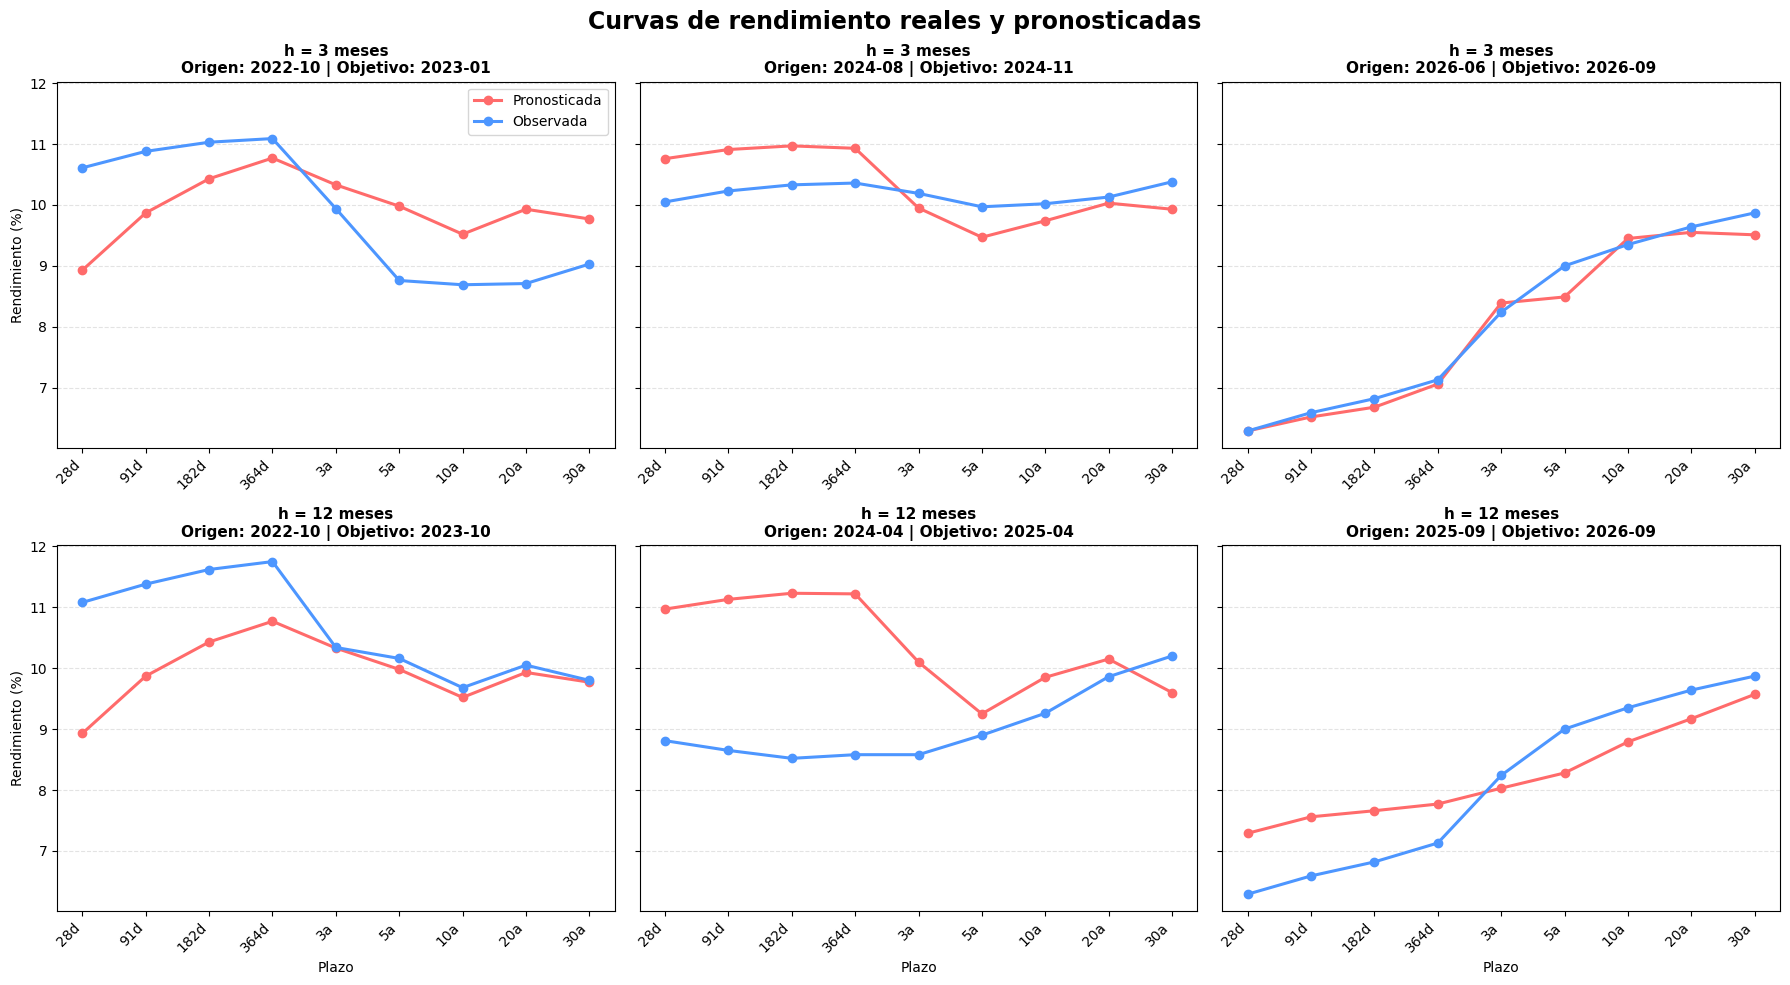

In [59]:
import matplotlib.pyplot as plt
import pandas as pd

# ============================================================
# Parámetros
# ============================================================

plazos = [
    "28d", "91d", "182d", "364d",
    "3a", "5a", "10a", "20a", "30a"
]

modelo = "Persistencia"
horizontes = [3, 12]

# ============================================================
# Crear figura
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10),
    sharey=True
)

for fila, horizonte in enumerate(horizontes):

    pronosticos = pronosticos_benchmark[horizonte][modelo]
    observados = observados_benchmark[horizonte]

    # Seleccionar tres orígenes: inicial, intermedio y final
    indices = [
        0,
        len(pronosticos) // 2,
        len(pronosticos) - 1
    ]

    for columna, posicion in enumerate(indices):

        ax = axes[fila, columna]

        origen = pronosticos.index[posicion]
        fecha_objetivo = (
            origen
            + pd.DateOffset(months=horizonte)
        )

        curva_pronosticada = (
            pronosticos.loc[origen, plazos]
        )

        curva_observada = (
            observados.loc[origen, plazos]
        )

        # Curva pronosticada
        ax.plot(
            plazos,
            curva_pronosticada.values,
            marker="o",
            linewidth=2.2,
            color="#FF6B6B",
            label="Pronosticada"
        )

        # Curva real observada
        ax.plot(
            plazos,
            curva_observada.values,
            marker="o",
            linewidth=2.2,
            color="#4D96FF",
            label="Observada"
        )

        ax.set_title(
            f"h = {horizonte} meses\n"
            f"Origen: {origen.strftime('%Y-%m')} | "
            f"Objetivo: {fecha_objetivo.strftime('%Y-%m')}",
            fontsize=11,
            fontweight="bold"
        )

        ax.set_xticks(range(len(plazos)))
        ax.set_xticklabels(
            plazos,
            rotation=45,
            ha="right"
        )

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.35
        )

        if columna == 0:
            ax.set_ylabel(
                "Rendimiento (%)"
            )

        if fila == 1:
            ax.set_xlabel(
                "Plazo"
            )

        if fila == 0 and columna == 0:
            ax.legend()

fig.suptitle(
    "Curvas de rendimiento reales y pronosticadas",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/curvas_reales_pronosticadas_h3_h12.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "outputs/figures/curvas_reales_pronosticadas_h3_h12.pdf",
    bbox_inches="tight"
)

plt.show()

**Lectura de las curvas pronosticadas**

La persistencia reproduce razonablemente el nivel y la forma general de algunas curvas, especialmente en el horizonte de tres meses y en el último periodo observado. Sin embargo, presenta desviaciones importantes cuando la curva cambia de nivel o de pendiente.

En el horizonte de doce meses, las diferencias son mayores: el modelo tiende a sobreestimar los plazos cortos y subestimar los largos cuando la curva se empina, o a mantener niveles que ya no corresponden al periodo objetivo. Por tanto, la persistencia es una referencia útil, pero no captura por completo los cambios futuros en la forma de la curva.


## Módulo 5 — Pronóstico multivariado con VAR(1)

Los benchmarks muestran que la persistencia es una referencia difícil de superar. En este módulo se incorpora un modelo que utiliza simultáneamente la información de los nueve plazos y se evalúa contra esa referencia.


**¿Por qué VAR(1)?**
Un VAR (vector autorregresivo) pronostica varias series simultáneamente usando sus valores pasados y los de las demás. En este análisis se aplica a los cambios mensuales de las tasas de los nueve plazos. Así se evalúa si sus movimientos pasados, considerados conjuntamente, permiten pronosticar mejor que la persistencia, que supone que las tasas se mantienen en su último nivel.

Pasos:
1. Preparar datos.
2. Estimar el VAR(1) en cada origen.
3. Reconstruir las curvas pronosticadas.
4. Evaluar el VAR(1).
5. Visualizar e interpretar los resultados.


### Paso 1 — Preparar datos

La base en niveles comienza en noviembre de 2006. Al calcular las diferencias mensuales, el cambio de noviembre requiere el dato de octubre, que queda fuera del periodo recortado. Por eso, tras eliminar ese valor indefinido, los cambios utilizados por el VAR comienzan efectivamente en diciembre de 2006.

In [60]:
# Preparación de la base VAR

plazos_var = [
    '28d', '91d', '182d', '364d',
    '3a', '5a', '10a', '20a', '30a'
]

# Se aplica forward-fill antes del recorte temporal para conservar
# observaciones previas disponibles sin usar información futura.
base_var = (
    tasas_mensuales_por_plazo[plazos_var]
    .ffill()
    .loc['2006-11-01':]
    .dropna()
)

base_var.index = pd.to_datetime(base_var.index)
base_var = base_var.sort_index()

# Cambios mensuales para el VAR(1).
# La diferencia de noviembre no se calcula porque octubre quedó fuera de base_var; dropna() la elimina.
cambios_var = base_var.diff().dropna()

print('Inicio de niveles:', base_var.index.min().strftime('%Y-%m'))
print('Fin de niveles:', base_var.index.max().strftime('%Y-%m'))
print('Observaciones en niveles:', len(base_var))
print('Observaciones en cambios:', len(cambios_var))
print('Número de plazos:', len(plazos_var))
print('Faltantes en niveles:', int(base_var.isna().sum().sum()))
print('Faltantes en cambios:', int(cambios_var.isna().sum().sum()))

display(base_var.head())
display(cambios_var.head())


Inicio de niveles: 2006-11
Fin de niveles: 2026-09
Observaciones en niveles: 239
Observaciones en cambios: 238
Número de plazos: 9
Faltantes en niveles: 0
Faltantes en cambios: 0


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2006-11-01,7.04,7.16,7.26,7.28,7.39,7.50,7.88,7.95,8.08
2006-12-01,7.04,7.16,7.20,7.27,7.18,7.28,7.56,7.57,8.08
2007-01-01,7.04,7.19,7.31,7.46,7.70,7.52,7.43,7.93,8.08
2007-02-01,7.04,7.19,7.34,7.38,7.47,7.70,7.96,7.93,7.71
2007-03-01,7.04,7.21,7.38,7.52,7.52,7.69,7.82,7.99,7.71


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2006-12-01,0.00,0.00,-0.06,-0.01,-0.21,-0.22,-0.32,-0.38,0.00
2007-01-01,0.00,0.03,0.11,0.19,0.52,0.24,-0.13,0.36,0.00
2007-02-01,0.00,0.00,0.03,-0.08,-0.23,0.18,0.53,0.00,-0.37
2007-03-01,0.00,0.02,0.04,0.14,0.05,-0.01,-0.14,0.06,0.00
2007-04-01,-0.03,-0.06,-0.11,-0.14,-0.08,-0.24,-0.20,-0.42,0.00


### Paso 2 — Estimar el VAR(1) en cada origen

El modelo se reestimará en cada origen de prueba utilizando únicamente la información disponible hasta ese mes. Esto mantiene la evaluación fuera de muestra y evita información futura.


In [61]:
# Estimación rolling del VAR(1)

from statsmodels.tsa.api import VAR

fecha_inicio_prueba_var = pd.Timestamp('2022-10-01')
horizontes_var = [3, 12]
pronosticos_var_cambios = {}

for horizonte in horizontes_var:
    ultima_fecha_origen = (
        base_var.index.max()
        - pd.DateOffset(months=horizonte)
    )

    origenes = base_var.index[
        (base_var.index >= fecha_inicio_prueba_var)
        & (base_var.index <= ultima_fecha_origen)
    ]

    pronosticos = {}

    for origen in origenes:
        cambios_entrenamiento = (
            cambios_var.loc[:origen, plazos_var]
            .dropna()
        )

        modelo_var = VAR(cambios_entrenamiento)
        ajuste_var = modelo_var.fit(
            maxlags=1,
            trend='c'
        )

        ultimo_estado = (
            cambios_entrenamiento
            .iloc[-ajuste_var.k_ar:]
            .to_numpy()
        )

        cambios_futuros = ajuste_var.forecast(
            y=ultimo_estado,
            steps=horizonte
        )

        pronosticos[origen] = cambios_futuros

    pronosticos_var_cambios[horizonte] = {
        'origenes': origenes,
        'cambios_pronosticados': pronosticos
    }

    print(f'\nh = {horizonte} meses')
    print('Orígenes utilizados:', len(origenes))
    print('Primer origen:', origenes.min().strftime('%Y-%m'))
    print('Último origen:', origenes.max().strftime('%Y-%m'))



h = 3 meses
Orígenes utilizados: 45
Primer origen: 2022-10
Último origen: 2026-06

h = 12 meses
Orígenes utilizados: 36
Primer origen: 2022-10
Último origen: 2025-09


### Paso 3 — Reconstruir las curvas pronosticadas

Los cambios pronosticados se acumularán a partir del último nivel conocido en cada origen. El resultado será una curva pronosticada para cada horizonte y origen.


In [62]:
# Reconstrucción de niveles a partir de cambios pronosticados

pronosticos_var_niveles = {}
observados_var = {}

for horizonte in horizontes_var:
    origenes = pronosticos_var_cambios[horizonte]['origenes']

    pronosticos_niveles = pd.DataFrame(
        index=origenes, columns=plazos_var, dtype=float
    )
    observados_niveles = pd.DataFrame(
        index=origenes, columns=plazos_var, dtype=float
    )

    for origen in origenes:
        nivel_origen = base_var.loc[
            origen, plazos_var
        ].to_numpy()

        cambios_futuros = pd.DataFrame(
            pronosticos_var_cambios[horizonte]
            ['cambios_pronosticados'][origen],
            columns=plazos_var
        )

        niveles_futuros = (
            nivel_origen
            + cambios_futuros.cumsum(axis=0)
        )

        pronosticos_niveles.loc[origen, plazos_var] = (
            niveles_futuros.iloc[-1].to_numpy()
        )

        fecha_objetivo = (
            origen + pd.DateOffset(months=horizonte)
        )

        observados_niveles.loc[origen, plazos_var] = (
            base_var.loc[fecha_objetivo, plazos_var]
        )

    pronosticos_var_niveles[horizonte] = pronosticos_niveles
    observados_var[horizonte] = observados_niveles

    print(f'\nh = {horizonte} meses')
    print('Pronósticos:', pronosticos_niveles.shape)
    print('Observados:', observados_niveles.shape)
    print('Faltantes en pronósticos:', int(pronosticos_niveles.isna().sum().sum()))
    print('Faltantes en observados:', int(observados_niveles.isna().sum().sum()))

print('Muestra de curva VAR(1) pronosticada, h = 3:')
display(pronosticos_var_niveles[3].head().round(3))

print('Curvas observadas correspondientes:')
display(observados_var[3].head().round(3))



h = 3 meses
Pronósticos: (45, 9)
Observados: (45, 9)
Faltantes en pronósticos: 0
Faltantes en observados: 0

h = 12 meses
Pronósticos: (36, 9)
Observados: (36, 9)
Faltantes en pronósticos: 0
Faltantes en observados: 0
Muestra de curva VAR(1) pronosticada, h = 3:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,9.694,10.663,11.259,11.597,10.806,10.527,9.862,10.252,10.275
2022-11-01,9.680,10.432,10.859,10.984,9.905,9.785,9.607,9.250,9.760
2022-12-01,10.485,11.118,11.364,11.415,9.964,9.847,9.266,9.101,9.392
2023-01-01,11.227,11.516,11.602,11.599,10.177,8.984,8.712,8.684,8.882
2023-02-01,11.636,11.978,12.162,12.228,10.390,9.716,9.290,8.655,9.009


Curvas observadas correspondientes:


,28d,91d,182d,364d,3a,5a,10a,20a,30a
mes,,,,,,,,,
2022-10-01,10.61,10.88,11.03,11.09,9.94,8.76,8.69,8.71,9.03
2022-11-01,10.92,11.29,11.54,11.66,9.96,9.75,9.38,8.71,8.85
2022-12-01,11.23,11.59,11.82,11.88,10.86,9.77,9.38,9.36,9.35
2023-01-01,11.29,11.55,11.70,11.77,10.50,9.20,8.89,9.07,9.35
2023-02-01,11.32,11.51,11.58,11.55,10.46,9.10,8.76,9.07,9.12


### Paso 4 — Evaluar el VAR(1)

Se calcularán RMSE y MAE por horizonte y plazo, utilizando la misma muestra de prueba empleada para los benchmarks.

**Validación:** comparar directamente el VAR(1) con persistencia, promedio histórico y promedio móvil de 12 meses.


Tabla resumen:


,horizonte_meses,modelo,RMSE,MAE
1,3,VAR(1),0.5103,0.3992
0,3,Persistencia,0.5499,0.4450
2,12,Persistencia,1.2723,1.0584
3,12,VAR(1),1.2808,1.0680


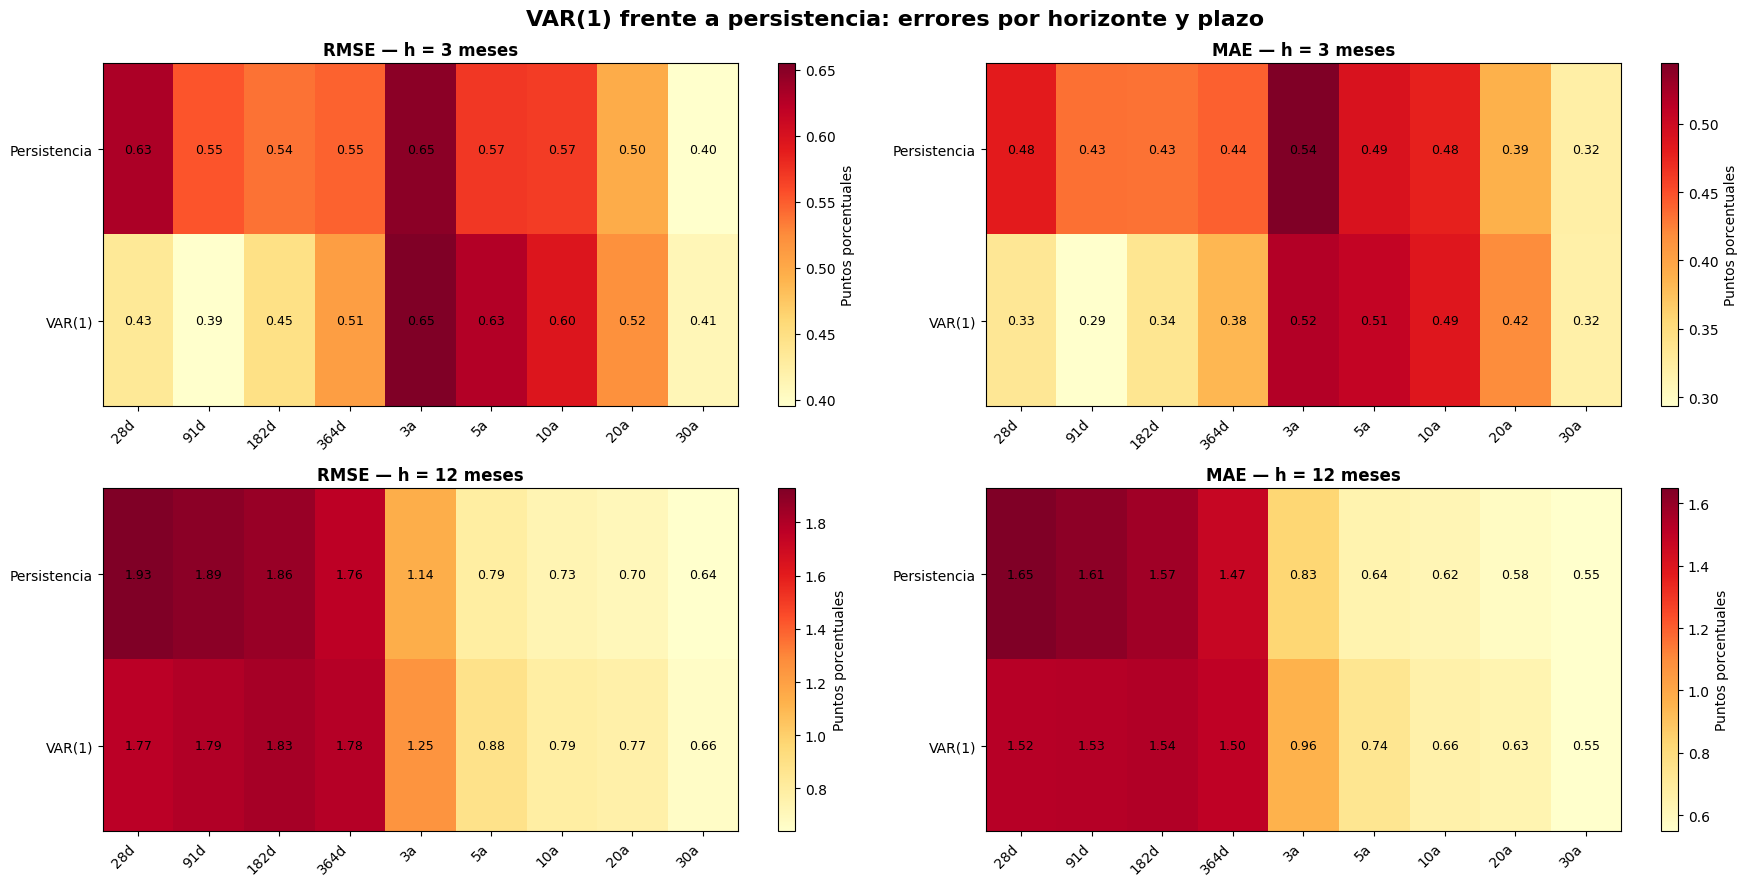

In [63]:
# Evaluación del VAR(1) frente al benchmark ganador

import numpy as np

resultados_var = []

for horizonte in horizontes_var:
    pronostico = pronosticos_var_niveles[horizonte]
    observado = observados_var[horizonte]

    for plazo in plazos_var:
        errores = (observado[plazo] - pronostico[plazo]).dropna()
        resultados_var.append({
            'horizonte_meses': horizonte,
            'modelo': 'VAR(1)',
            'plazo': plazo,
            'RMSE': np.sqrt(np.mean(errores ** 2)),
            'MAE': np.mean(np.abs(errores)),
            'observaciones': len(errores)
        })

resultados_var = pd.DataFrame(resultados_var)

# Comparar únicamente con la persistencia, el benchmark ganador.
resultados_comparacion = pd.concat([
    resultados_evaluacion[
        resultados_evaluacion['modelo'] == 'Persistencia'
    ],
    resultados_var
], ignore_index=True)

resumen_var_benchmark = (
    resultados_comparacion
    .groupby(['horizonte_meses', 'modelo'], as_index=False)[['RMSE', 'MAE']]
    .mean()
)

print('Tabla resumen:')
display(
    resumen_var_benchmark
    .sort_values(['horizonte_meses', 'RMSE'])
    .round(4)
)

orden_modelos_var = ['Persistencia', 'VAR(1)']

def mapa_error_var(resultados, horizonte, metrica, ax):
    tabla = (
        resultados[resultados['horizonte_meses'] == horizonte]
        .pivot(index='modelo', columns='plazo', values=metrica)
        .reindex(index=orden_modelos_var, columns=plazos_var)
    )

    imagen = ax.imshow(tabla.values, cmap='YlOrRd', aspect='auto')
    ax.set_title(f'{metrica} — h = {horizonte} meses', fontweight='bold')
    ax.set_xticks(range(len(plazos_var)))
    ax.set_xticklabels(plazos_var, rotation=45, ha='right')
    ax.set_yticks(range(len(orden_modelos_var)))
    ax.set_yticklabels(orden_modelos_var)

    for fila in range(tabla.shape[0]):
        for columna in range(tabla.shape[1]):
            ax.text(columna, fila, f'{tabla.iloc[fila, columna]:.2f}',
                    ha='center', va='center', fontsize=9)

    plt.colorbar(imagen, ax=ax, label='Puntos porcentuales')

fig, axes = plt.subplots(2, 2, figsize=(18, 9))

for fila, horizonte in enumerate(horizontes_var):
    mapa_error_var(resultados_comparacion, horizonte, 'RMSE', axes[fila, 0])
    mapa_error_var(resultados_comparacion, horizonte, 'MAE', axes[fila, 1])

fig.suptitle('VAR(1) frente a persistencia: errores por horizonte y plazo',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


In [64]:
# Comparación puntual RMSE y MAE
comparacion_puntual = (
    resultados_comparacion
    .groupby(
        ["horizonte_meses", "modelo"]
    )[["RMSE", "MAE"]]
    .mean()
    .round(4)
)

for horizonte in [3, 12]:

    print(f"\nh = {horizonte} meses")

    for modelo in ["Persistencia", "VAR(1)"]:

        rmse = comparacion_puntual.loc[
            (horizonte, modelo),
            "RMSE"
        ]

        mae = comparacion_puntual.loc[
            (horizonte, modelo),
            "MAE"
        ]

        print(
            f"{modelo}: RMSE = {rmse:.4f} | "
            f"MAE = {mae:.4f}"
        )


h = 3 meses
Persistencia: RMSE = 0.5499 | MAE = 0.4450
VAR(1): RMSE = 0.5103 | MAE = 0.3992

h = 12 meses
Persistencia: RMSE = 1.2723 | MAE = 1.0584
VAR(1): RMSE = 1.2808 | MAE = 1.0680


Resultado del VAR(1). Con el tratamiento corregido, el VAR(1) obtuvo menores errores que la persistencia a 3 meses (RMSE: 0.5103 vs. 0.5499; MAE: 0.3992 vs. 0.4450). A 12 meses, sus errores fueron ligeramente mayores (RMSE: 1.2808 vs. 1.2723; MAE: 1.0680 vs. 1.0584).



### Paso 5 — Visualizar e interpretar

Se comparan las curvas reales con las curvas pronosticadas y se revisa la diferencia de errores frente a los benchmarks. El objetivo es determinar si la información conjunta de los plazos aporta valor y si ese valor depende del horizonte de pronóstico.


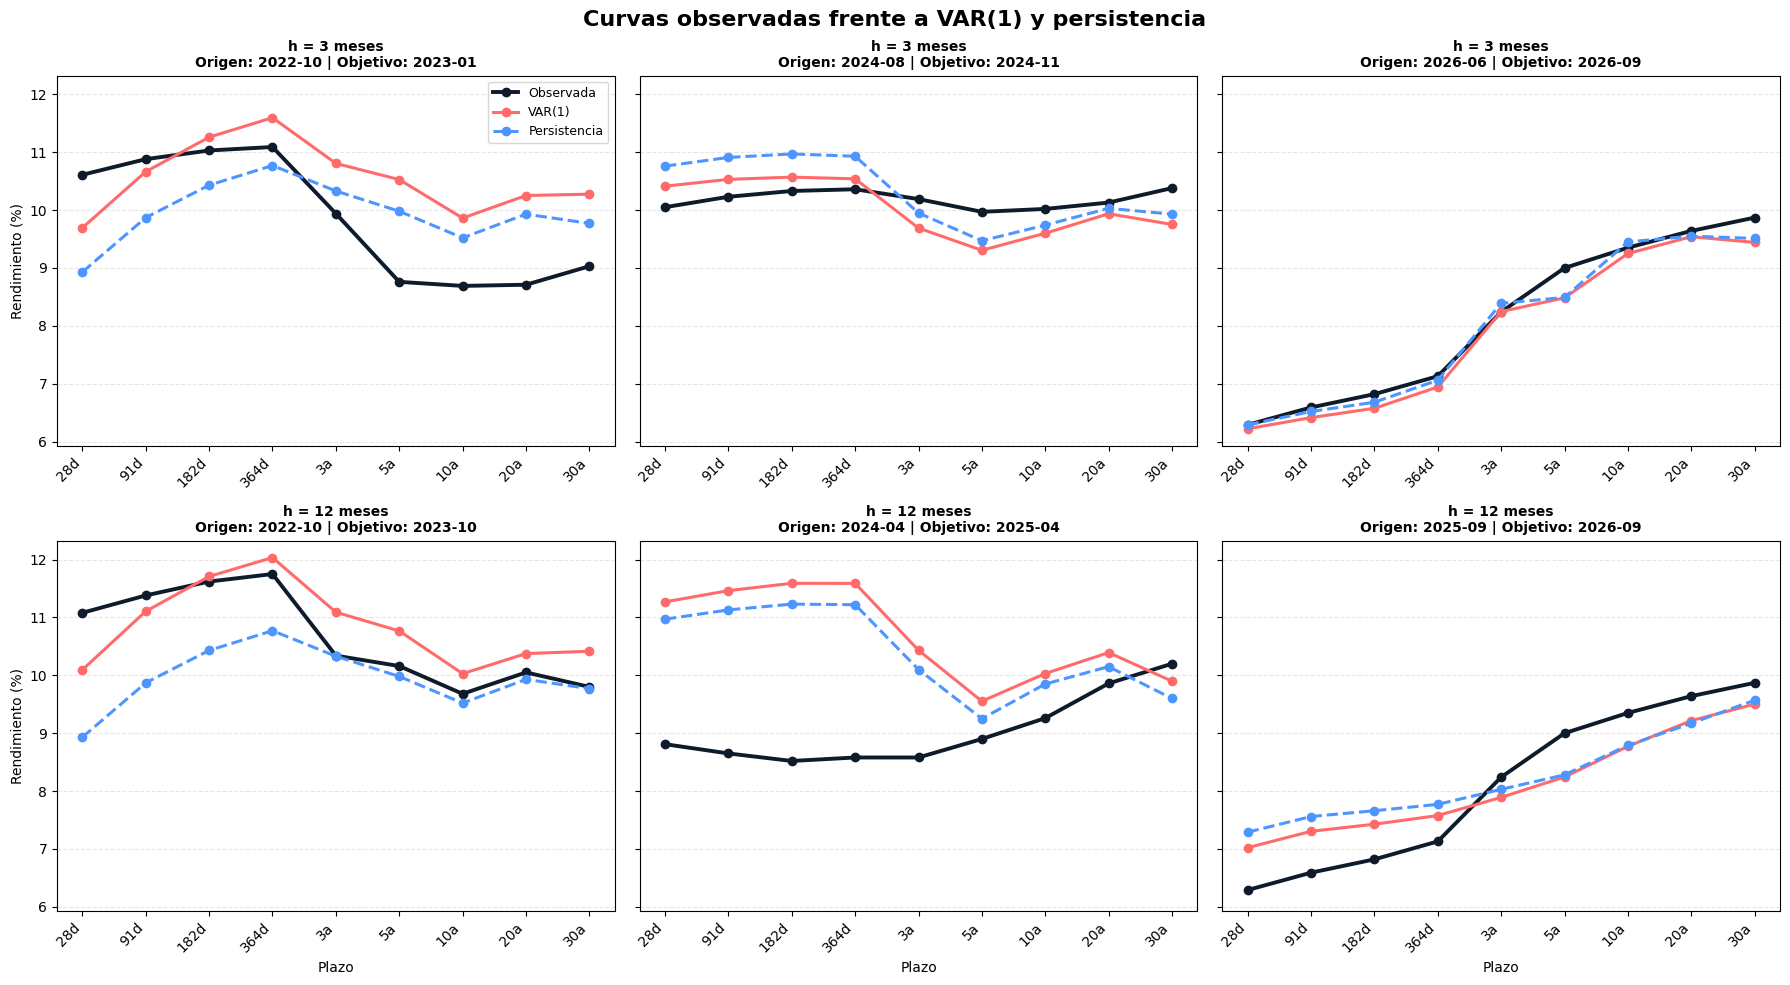

In [65]:
# Visualización de curvas reales frente a VAR(1) y persistencia

fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True)

for fila, horizonte in enumerate(horizontes_var):
    pronostico_var = pronosticos_var_niveles[horizonte]
    observado = observados_var[horizonte]
    persistencia = pronosticos_benchmark[horizonte]['Persistencia']
    posiciones = [0, len(pronostico_var) // 2, len(pronostico_var) - 1]

    for columna, posicion in enumerate(posiciones):
        ax = axes[fila, columna]
        origen = pronostico_var.index[posicion]
        fecha_objetivo = origen + pd.DateOffset(months=horizonte)
        ax.plot(plazos_var, observado.loc[origen, plazos_var], marker='o', linewidth=2.8, color='#0E1B2A', label='Observada')
        ax.plot(plazos_var, pronostico_var.loc[origen, plazos_var], marker='o', linewidth=2.2, color='#FF6B6B', label='VAR(1)')
        ax.plot(plazos_var, persistencia.loc[origen, plazos_var], marker='o', linewidth=2.2, linestyle='--', color='#4D96FF', label='Persistencia')
        ax.set_title(f'h = {horizonte} meses\nOrigen: {origen:%Y-%m} | Objetivo: {fecha_objetivo:%Y-%m}', fontsize=10, fontweight='bold')
        ax.set_xticks(range(len(plazos_var)))
        ax.set_xticklabels(plazos_var, rotation=45, ha='right')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        if columna == 0:
            ax.set_ylabel('Rendimiento (%)')
        if fila == 1:
            ax.set_xlabel('Plazo')
        if fila == 0 and columna == 0:
            ax.legend(fontsize=9)

fig.suptitle('Curvas observadas frente a VAR(1) y persistencia', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/figures/curvas_var_vs_persistencia.png', dpi=600, bbox_inches='tight')
plt.savefig('outputs/figures/curvas_var_vs_persistencia.pdf', bbox_inches='tight')
plt.show()


**Conclusión del Módulo 5.** El VAR(1) obtuvo menores errores que la persistencia a 3 meses, pero a 12 meses sus resultados fueron ligeramente peores. La comparación es exploratoria: los cambios se calcularon sobre tasas completadas con forward-fill, que puede introducir ceros artificiales. Además, no se compararon otros órdenes del VAR; por tanto, no se concluye que VAR(1) sea la especificación óptima.



## Módulo 6 — Pronóstico estructural con PCA + VAR(1)

El Módulo 6 prueba si se pueden pronosticar las nueve tasas usando solo tres series resumidas (estructura a través de PCA). Primero, el PCA resume las tasas de los nueve plazos en tres componentes. Luego, un VAR(1) pronostica esos componentes a 3 y 12 meses. Finalmente, se usan esos pronósticos para reconstruir las nueve tasas y compararlas con las observadas. El proceso se repite en cada fecha de pronóstico usando únicamente datos anteriores a esa fecha.

1. Estimar el PCA en cada origen: 
2. Pronosticar los factores:
3. Reconstruir las curvas: convertir los componentes pronosticados en tasas para los nueve plazos.
4. Evaluar el pronóstico estructural: comparar las tasas pronosticadas con las observadas.
5. Visualización y conclusión: mostrar y resumir los resultados.

### Fundamento técnico

El PCA identifica la estructura común de la curva, pero no pronostica por sí mismo. Por eso se pronosticarán los tres puntajes principales con un VAR(1) y después se reconstruirán los nueve rendimientos.


### Paso 1 — Estimar el PCA en cada origen

En cada origen se utilizará únicamente la información disponible hasta ese mes. Se conservarán tres componentes y se guardarán la media, las cargas y los puntajes del PCA.


In [66]:
# Volver a estimar PCA para cada cada origen
from sklearn.decomposition import PCA

n_componentes_estructural = 3
fecha_inicio_prueba_pca = pd.Timestamp('2022-10-01')
horizontes_pca = [3, 12]
pca_por_origen = {}
scores_pca_por_origen = {}
origenes_pca = {}

for horizonte in horizontes_pca:
    ultima_fecha_origen = base_var.index.max() - pd.DateOffset(months=horizonte)
    origenes = base_var.index[(base_var.index >= fecha_inicio_prueba_pca) & (base_var.index <= ultima_fecha_origen)]
    origenes_pca[horizonte] = origenes
    pca_por_origen[horizonte] = {}
    scores_pca_por_origen[horizonte] = {}
    for origen in origenes:
        niveles_entrenamiento = base_var.loc[:origen, plazos_var].dropna()
        modelo_pca = PCA(n_components=n_componentes_estructural)
        scores = modelo_pca.fit_transform(niveles_entrenamiento)
        pca_por_origen[horizonte][origen] = modelo_pca
        scores_pca_por_origen[horizonte][origen] = pd.DataFrame(scores, index=niveles_entrenamiento.index, columns=[f'PC{i}' for i in range(1, n_componentes_estructural + 1)])
    print(f'h = {horizonte} meses | origenes PCA: {len(origenes)} | componentes: {n_componentes_estructural}')

# Tabla de control: el PCA transforma nueve plazos en tres factores.
resumen_paso1_pca = pd.DataFrame([
    {'horizonte_meses': h, 'origenes': len(origenes_pca[h]), 'observaciones_entrenamiento_ultimo_origen': len(scores_pca_por_origen[h][origenes_pca[h][-1]]), 'factores_conservados': n_componentes_estructural}
    for h in horizontes_pca
])
display(resumen_paso1_pca)
print('Objeto producido: pca_por_origen y scores_pca_por_origen; todavía no hay pronósticos de factores ni curvas pronosticadas.')
# Se implementará después de revisar esta estructura.


h = 3 meses | origenes PCA: 45 | componentes: 3
h = 12 meses | origenes PCA: 36 | componentes: 3


,horizonte_meses,origenes,observaciones_entrenamiento_ultimo_origen,factores_conservados
0,3,45,236,3
1,12,36,227,3


Objeto producido: pca_por_origen y scores_pca_por_origen; todavía no hay pronósticos de factores ni curvas pronosticadas.


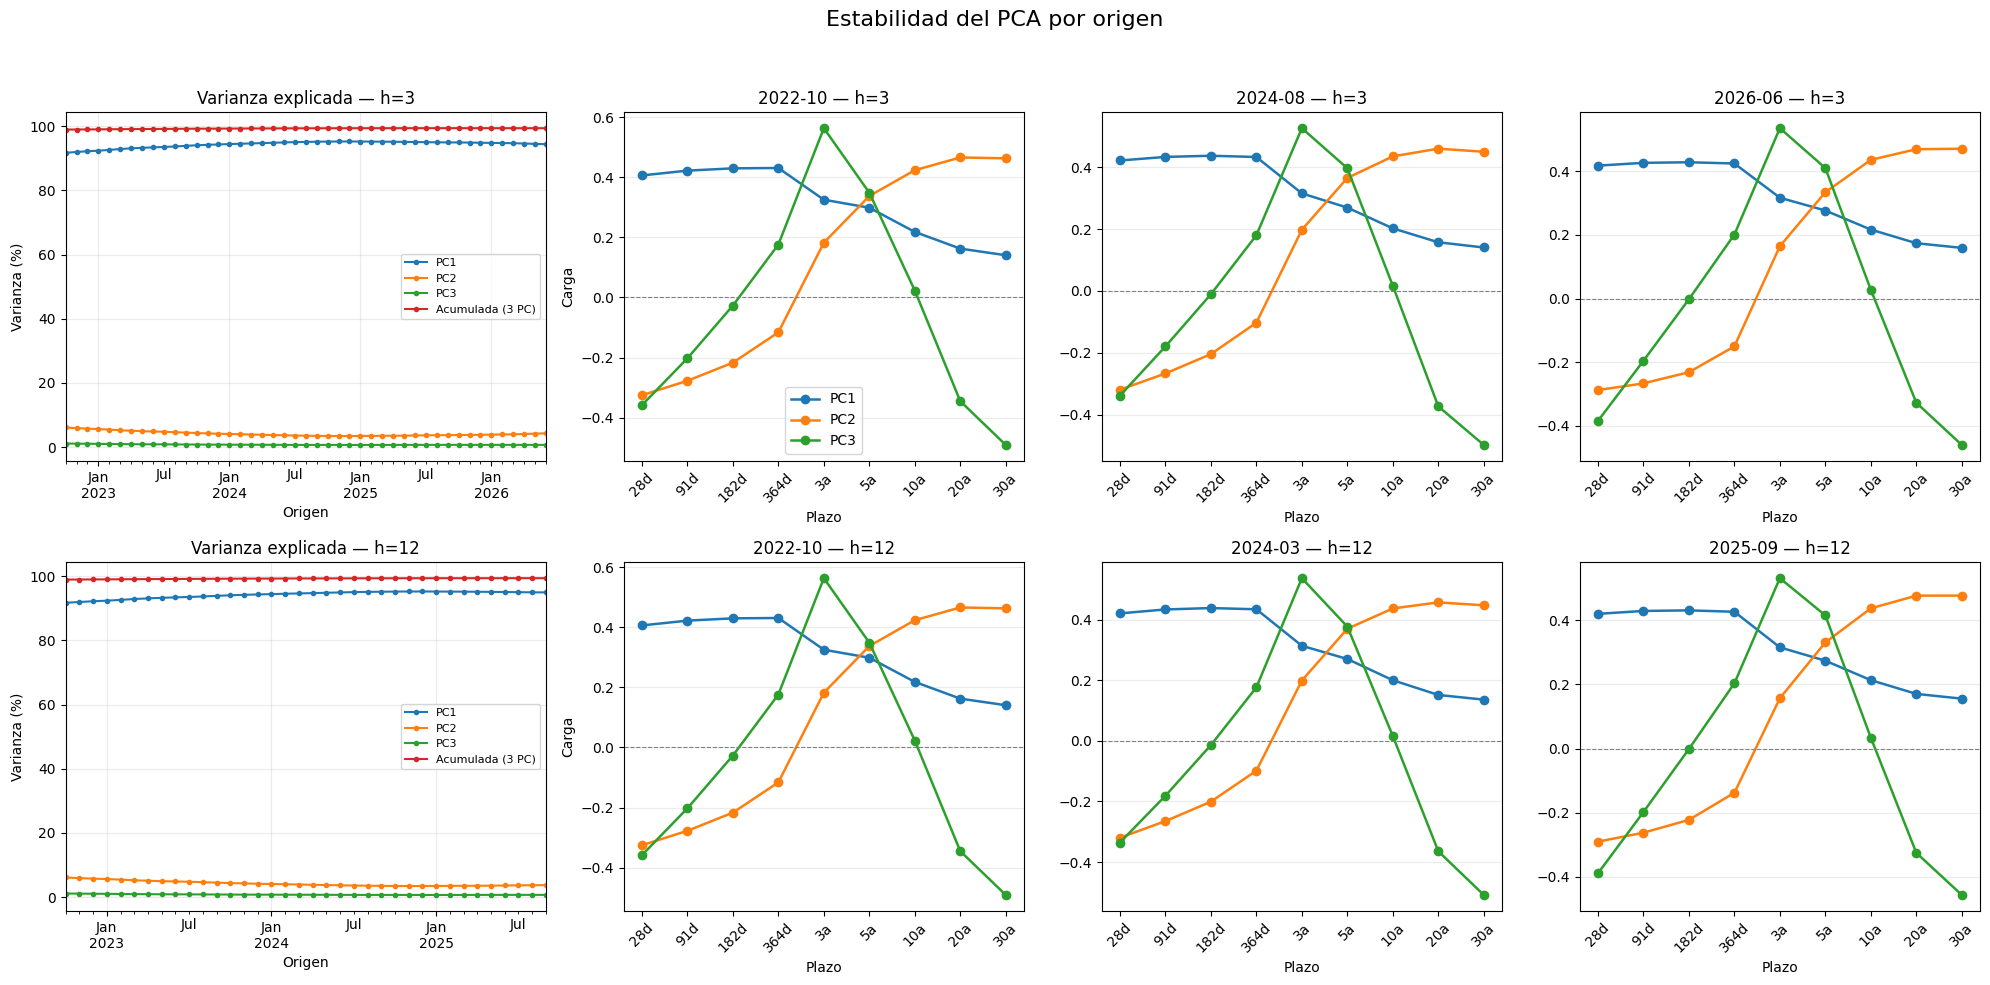

In [67]:
# Visualizar la evolución de la varianza explicada y las cargas
n_ejemplos = 3
fig, axes = plt.subplots(
    2, 4,
    figsize=(20, 10),
    gridspec_kw={"width_ratios": [1.2, 1, 1, 1]}
)

for fila, horizonte in enumerate(horizontes_pca):
    origenes = origenes_pca[horizonte]

    # Elegir orígenes inicial, intermedio y final para mostrar las cargas.
    posiciones = np.unique(
        np.linspace(0, len(origenes) - 1,
                    min(n_ejemplos, len(origenes)), dtype=int)
    )
    origenes_ejemplo = origenes[posiciones]

    # Graficar la varianza explicada por componente en cada origen.
    ax_var = axes[fila, 0]
    varianza = pd.DataFrame(
        {
            f"PC{i + 1}": [
                pca_por_origen[horizonte][origen]
                .explained_variance_ratio_[i] * 100
                for origen in origenes
            ]
            for i in range(n_componentes_estructural)
        },
        index=origenes
    )

    varianza["Acumulada (3 PC)"] = varianza.sum(axis=1)
    varianza.plot(ax=ax_var, marker=".", linewidth=1.5)

    ax_var.set_title(f"Varianza explicada — h={horizonte}")
    ax_var.set_ylabel("Varianza (%)")
    ax_var.set_xlabel("Origen")
    ax_var.grid(alpha=0.25)
    ax_var.legend(fontsize=8)

    # Copiar las cargas y alinear su signo entre orígenes seleccionados.
    cargas_previas = None

    for columna, origen in enumerate(origenes_ejemplo, start=1):
        modelo = pca_por_origen[horizonte][origen]
        cargas = modelo.components_[:n_componentes_estructural].copy()

        if cargas_previas is not None:
            for i in range(n_componentes_estructural):
                if np.dot(cargas[i], cargas_previas[i]) < 0:
                    cargas[i] *= -1

        cargas_previas = cargas.copy()
        ax = axes[fila, columna]

        for i in range(n_componentes_estructural):
            ax.plot(
                plazos_var,
                cargas[i],
                marker="o",
                linewidth=1.8,
                label=f"PC{i + 1}"
            )

        ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"{origen:%Y-%m} — h={horizonte}")
        ax.set_xlabel("Plazo")
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="x", rotation=45)

        if columna == 1:
            ax.set_ylabel("Carga")

        if fila == 0 and columna == 1:
            ax.legend()

fig.suptitle(
    "Estabilidad del PCA por origen",
    fontsize=16
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Comentarios:** La estructura del PCA se mantiene estable entre los orígenes: PC1 explica alrededor del 92–95% de la varianza y los tres componentes, cerca del 99%. Las cargas conservan perfiles similares a lo largo del tiempo y entre los horizontes de 3 y 12 meses. Esto sugiere que los factores resumen la curva de forma consistente, aunque aún no garantiza por sí mismo la precisión de los pronósticos.



### Paso 2 — Pronosticar los factores

Para cada fecha de origen, se estima un VAR(1) con los puntajes históricos de PC1, PC2 y PC3 disponibles hasta ese mes. El modelo usa los puntajes del mes anterior para pronosticar los tres factores conjuntamente. Repite el pronóstico mes a mes hasta alcanzar el horizonte de 3 o 12 meses. El resultado son puntajes futuros, no tasas: se convertirán en pronósticos para los nueve plazos en el Paso 3.

In [68]:
# VAR(1) sobre PC1, PC2 y PC3
from statsmodels.tsa.api import VAR

pronosticos_factores_pca = {}
for horizonte in horizontes_pca:
    pronosticos_factores_pca[horizonte] = {}
    for origen in origenes_pca[horizonte]:
        factores_entrenamiento = scores_pca_por_origen[horizonte][origen]
        ajuste_factores = VAR(factores_entrenamiento).fit(maxlags=1, trend='c')
        ultimo_estado = factores_entrenamiento.iloc[-ajuste_factores.k_ar:].to_numpy()
        pronosticos_factores_pca[horizonte][origen] = ajuste_factores.forecast(y=ultimo_estado, steps=horizonte)
    print(f'h = {horizonte} meses | pronosticos de factores: {len(pronosticos_factores_pca[horizonte])}')

# Tabla de control: aquí ya se pronostican factores, no tasas individuales.
ejemplo_origen_paso2 = origenes_pca[3][0]
tabla_factores_paso2 = pd.DataFrame(
    pronosticos_factores_pca[3][ejemplo_origen_paso2],
    columns=['PC1', 'PC2', 'PC3'],
)
tabla_factores_paso2.index = [f' t+{i}' for i in range(1, 4)]
print(f'Origen del ejemplo: {ejemplo_origen_paso2:%Y-%m} | horizonte: 3 meses')
display(tabla_factores_paso2.round(4))
print('Objeto producido: pronosticos_factores_pca; todavía no hay curvas reconstruidas.')

# ReconstrucciÃ³n de curvas y valores observados se realiza en el Paso 3.

# EvaluaciÃ³n: persistencia, VAR(1) directo y PCA + VAR(1)
# La evaluacion se realiza en el Paso 4.

# Curvas promedio: observado frente a los tres modelos
# Las visualizaciones se generan en el Paso 5.

# Las curvas completas se generan en el Paso 5.
# Se implementará después de validar el PCA rolling.


h = 3 meses | pronosticos de factores: 45
h = 12 meses | pronosticos de factores: 36
Origen del ejemplo: 2022-10 | horizonte: 3 meses


,PC1,PC2,PC3
t+1,11.3425,1.0156,0.1941
t+2,11.5804,0.8877,0.0992
t+3,11.7606,0.7661,0.0131


Objeto producido: pronosticos_factores_pca; todavía no hay curvas reconstruidas.


### Paso 3 — Reconstruir las curvas

El VAR pronostica los tres componentes principales, no las tasas de cada plazo directamente. En este paso, esos pronósticos se convierten de nuevo en tasas para los nueve plazos, usando las cargas y el promedio del PCA estimado en cada origen. Así se obtiene una curva pronosticada que puede compararse con la curva observada en la fecha objetivo.

In [69]:
# Reconstruccion de curvas y valores observados
pronosticos_pca_var_niveles = {}
observados_pca_var = {}
for horizonte in horizontes_pca:
    origenes = origenes_pca[horizonte]
    pronostico = pd.DataFrame(index=origenes, columns=plazos_var, dtype=float)
    observado = pd.DataFrame(index=origenes, columns=plazos_var, dtype=float)
    for origen in origenes:
        modelo_pca = pca_por_origen[horizonte][origen]
        factores_finales = pronosticos_factores_pca[horizonte][origen][-1, :]
        pronostico.loc[origen, plazos_var] = modelo_pca.inverse_transform(factores_finales.reshape(1, -1))[0]
        fecha_objetivo = origen + pd.DateOffset(months=horizonte)
        observado.loc[origen, plazos_var] = base_var.loc[fecha_objetivo, plazos_var].to_numpy()
    pronosticos_pca_var_niveles[horizonte] = pronostico
    # La tabla de control del Paso 3 se muestra después del bucle.
    observados_pca_var[horizonte] = observado
    print(f'h = {horizonte} meses | pronosticos reconstruidos: {pronostico.shape}')
# Reconstrucción de los nueve plazos
# Se implementará después de validar los pronósticos de factores.


h = 3 meses | pronosticos reconstruidos: (45, 9)
h = 12 meses | pronosticos reconstruidos: (36, 9)


### Paso 4 — Evaluar el pronóstico estructural

Se calcularán RMSE y MAE para cada plazo y horizonte, usando exactamente los mismos orígenes y fechas objetivo que en los benchmarks y el VAR(1) directo.


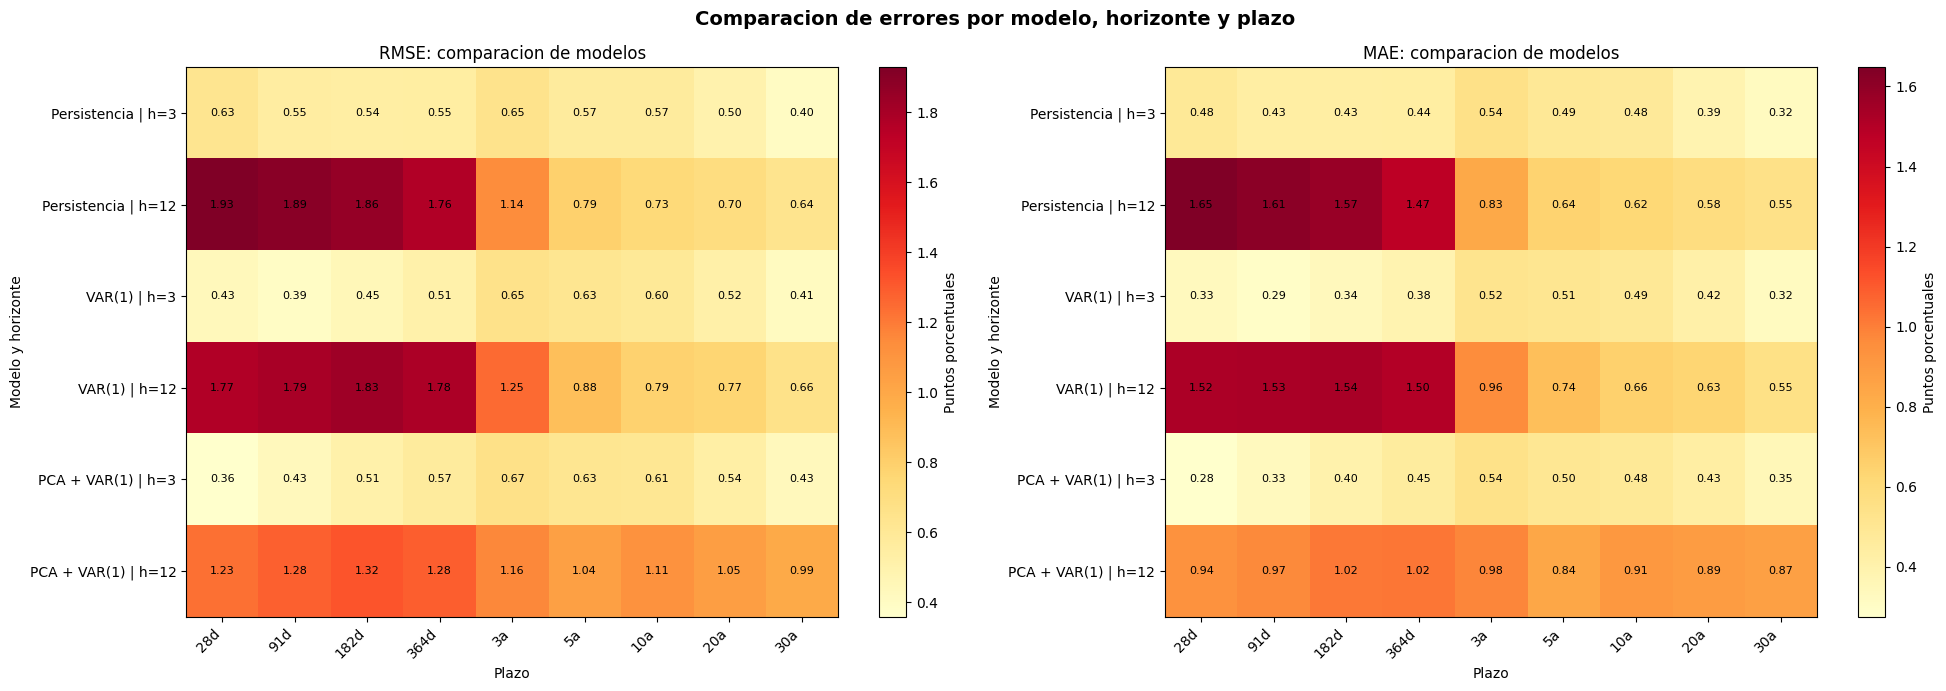

,horizonte_meses,modelo,RMSE,MAE
2,3,VAR(1),0.5103,0.3992
0,3,PCA + VAR(1),0.5266,0.4193
1,3,Persistencia,0.5499,0.4450
3,12,PCA + VAR(1),1.1630,0.9384
4,12,Persistencia,1.2723,1.0584
5,12,VAR(1),1.2808,1.0680


In [70]:
# Evaluacion frente a persistencia y VAR(1) directo
resultados_pca_var = []
for horizonte in horizontes_pca:
    for plazo in plazos_var:
        errores = (observados_pca_var[horizonte][plazo] - pronosticos_pca_var_niveles[horizonte][plazo]).dropna()
        resultados_pca_var.append({'horizonte_meses': horizonte, 'modelo': 'PCA + VAR(1)', 'plazo': plazo, 'RMSE': np.sqrt(np.mean(errores ** 2)), 'MAE': np.mean(np.abs(errores)), 'observaciones': len(errores)})
resultados_pca_var = pd.DataFrame(resultados_pca_var)
resultados_comparacion_pca = pd.concat([resultados_evaluacion[resultados_evaluacion['modelo'] == 'Persistencia'], resultados_var, resultados_pca_var], ignore_index=True)
resumen_pca_var = resultados_comparacion_pca.groupby(['horizonte_meses', 'modelo'])[['RMSE', 'MAE']].mean().round(4)


# Comparacion de modelos: persistencia, VAR directo y PCA + VAR
modelos_comparacion = ['Persistencia', 'VAR(1)', 'PCA + VAR(1)']
resultado_modelos = resultados_comparacion_pca[resultados_comparacion_pca['modelo'].isin(modelos_comparacion)]
orden_filas = [(modelo, horizonte) for modelo in modelos_comparacion for horizonte in horizontes_pca]
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, metrica in zip(axes, ['RMSE', 'MAE']):
    tabla = resultado_modelos.pivot_table(index=['modelo', 'horizonte_meses'], columns='plazo', values=metrica).reindex(index=orden_filas, columns=plazos_var)
    imagen = ax.imshow(tabla.to_numpy(), cmap='YlOrRd', aspect='auto')
    ax.set_title(f'{metrica}: comparacion de modelos')
    ax.set_xlabel('Plazo'); ax.set_ylabel('Modelo y horizonte')
    ax.set_xticks(range(len(plazos_var))); ax.set_xticklabels(plazos_var, rotation=45, ha='right')
    ax.set_yticks(range(len(orden_filas))); ax.set_yticklabels([f'{modelo} | h={h}' for modelo, h in orden_filas])
    for fila in range(tabla.shape[0]):
        for columna in range(tabla.shape[1]):
            ax.text(columna, fila, f'{tabla.iloc[fila, columna]:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(imagen, ax=ax, label='Puntos porcentuales')
fig.suptitle('Comparacion de errores por modelo, horizonte y plazo', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()
display(resumen_pca_var.reset_index().sort_values(['horizonte_meses', 'RMSE']))
# Evaluación frente a persistencia y VAR(1) directo
# Se implementará después de reconstruir las curvas.


**Resultado del pronóstico estructural-:** 
Conocer la estructura (PCA) sí ayuda, pero particularmente para el horizonte más largo:
- A 3 meses, PCA + VAR(1) mejora frente a la persistencia, pero no supera al VAR(1) directo. La reducción a nivel, pendiente y curvatura pierde algo de información útil en el corto plazo.
- A 12 meses, PCA + VAR(1) es el mejor modelo. Los factores comunes permiten capturar la dinámica de la curva y reducir el error frente a persistencia y VAR directo.
Conclusión: la estructura de la curva sí aporta valor, especialmente para pronósticos de mediano plazo, pero no sustituye al VAR directo en el horizonte corto.

### Paso 5 — Visualización y conclusión

Se mostrarán curvas reales y pronosticadas, mapas de calor de errores y una conclusión sobre si la estructura PCA mejora el pronóstico.


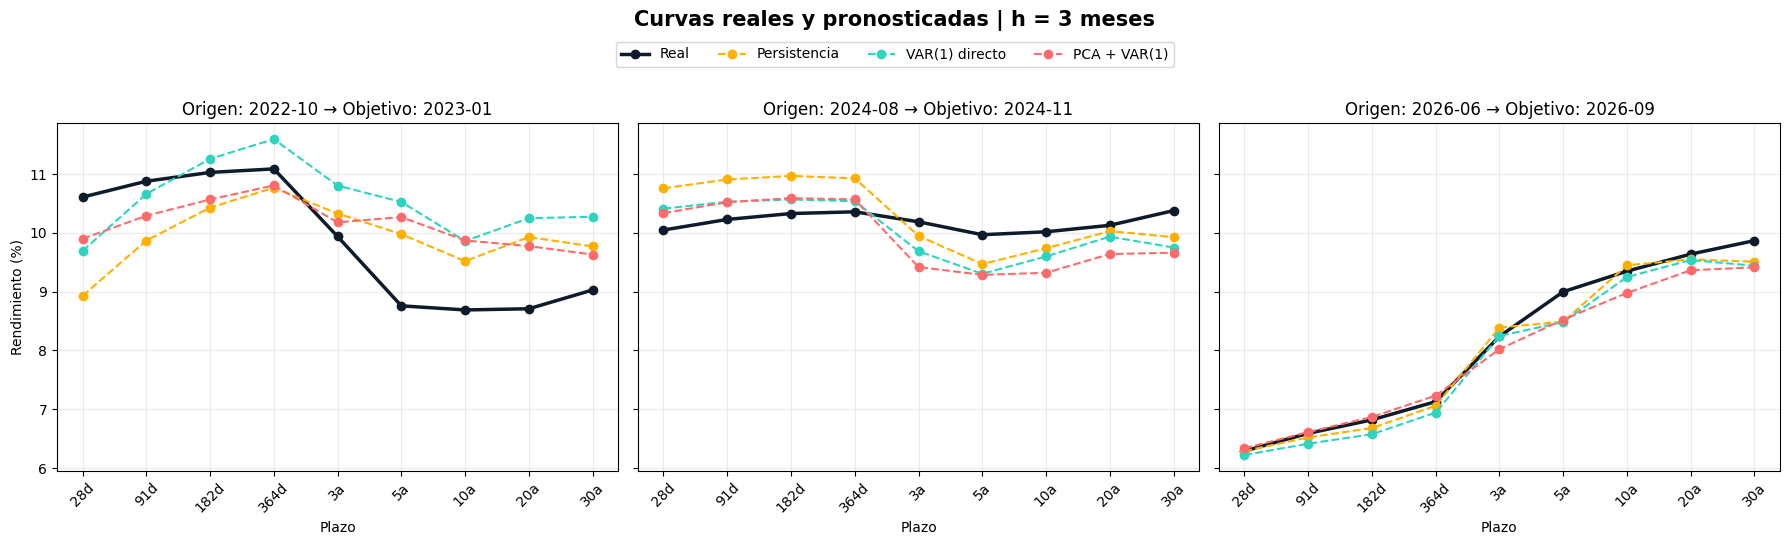

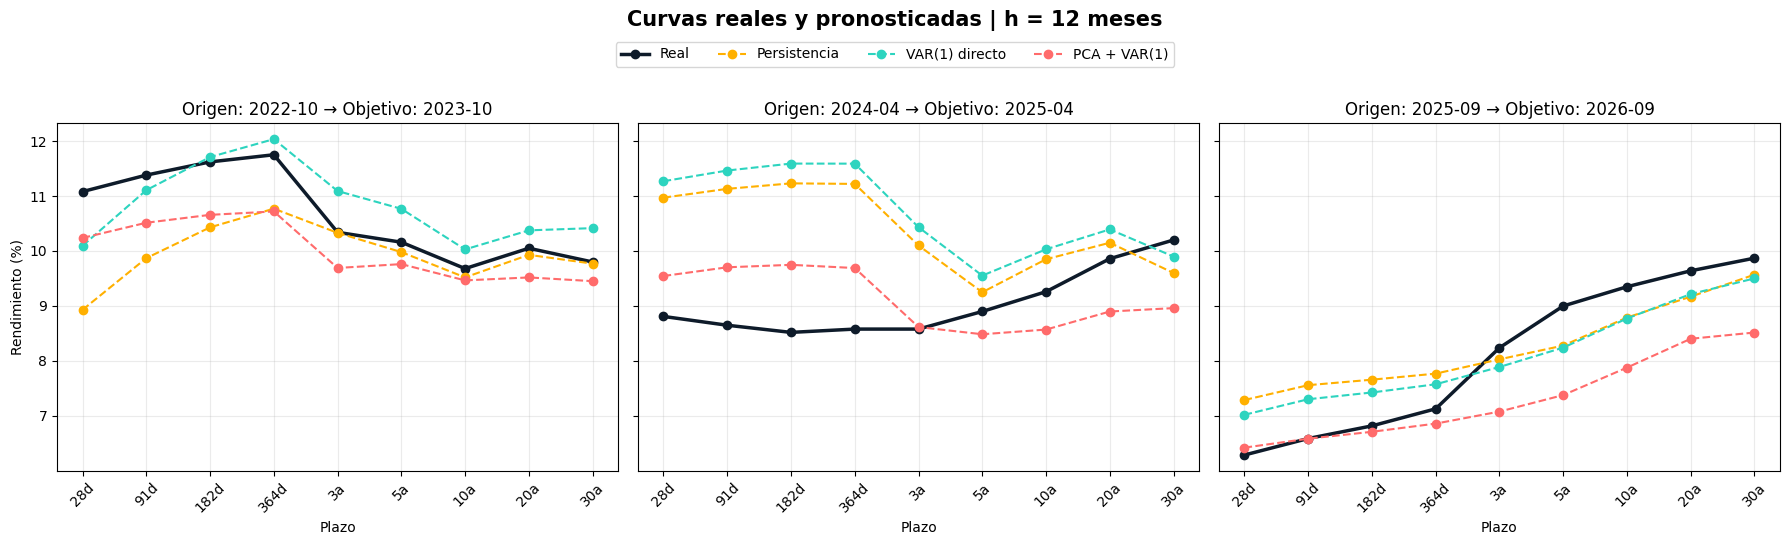

In [71]:
# Curvas representativas: inicio, mitad y final de cada horizonte
for horizonte in horizontes_pca:
    origenes = observados_pca_var[horizonte].index
    posiciones = [0, len(origenes) // 2, len(origenes) - 1]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    for ax, posicion in zip(axes, posiciones):
        origen = origenes[posicion]
        fecha_objetivo = origen + pd.DateOffset(months=horizonte)
        ax.plot(plazos_var, observados_pca_var[horizonte].loc[origen, plazos_var], marker='o', linewidth=2.5, color='#0E1B2A', label='Real')
        ax.plot(plazos_var, pronosticos_benchmark[horizonte]['Persistencia'].loc[origen, plazos_var], marker='o', linestyle='--', color='#FFB000', label='Persistencia')
        ax.plot(plazos_var, pronosticos_var_niveles[horizonte].loc[origen, plazos_var], marker='o', linestyle='--', color='#2DD4BF', label='VAR(1) directo')
        ax.plot(plazos_var, pronosticos_pca_var_niveles[horizonte].loc[origen, plazos_var], marker='o', linestyle='--', color='#FF6B6B', label='PCA + VAR(1)')
        ax.set_title(f'Origen: {origen:%Y-%m} → Objetivo: {fecha_objetivo:%Y-%m}')
        ax.set_xlabel('Plazo'); ax.grid(alpha=.25); ax.tick_params(axis='x', rotation=45)
    axes[0].set_ylabel('Rendimiento (%)')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.03))
    fig.suptitle(f'Curvas reales y pronosticadas | h = {horizonte} meses', y=1.08, fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.show()


# Resumen ejecutivo

## Objetivo y diseño del análisis

- **Qué se pronostica:** el nivel de los nueve plazos de la curva, de 28 días a 30 años, a 3 y 12 meses.
- **Información disponible:** en cada origen de prueba, el modelo utiliza únicamente los datos observados hasta ese mes.
- **Evaluación:** el entrenamiento inicia en noviembre de 2006 y la prueba avanza mes a mes desde octubre de 2022.
- **Tratamiento de faltantes:** se utiliza *forward-fill*; la decisión y sus limitaciones se documentan en el Módulo 2.

## Hallazgo 1 — La curva tiene una estructura común

Los nueve plazos están altamente correlacionados entre sí (mínimo 0.73 entre los extremos). El PCA muestra que tres factores —nivel, pendiente y curvatura— explican 99.4% del movimiento conjunto de la curva. El nivel explica 94% y presenta una correlación de 0.98 con la tasa objetivo de Banxico.

## Hallazgo 2 — La pronosticabilidad depende del horizonte

En los resultados obtenidos, el VAR(1) directo presenta menores errores que la persistencia a 3 meses; a 12 meses, sus errores son ligeramente mayores. El PCA + VAR(1) no supera al VAR(1) directo a 3 meses, pero a 12 meses obtiene el menor error promedio. Estos resultados son exploratorios, ya que el forward-fill puede introducir ceros en los cambios utilizados por los modelos.

## Hallazgo 3 — Conocer la estructura ayuda especialmente a 12 meses

Con el tratamiento corregido, el modelo PCA + VAR(1) no supera al VAR(1) directo a 3 meses (RMSE: 0.5266 frente a 0.5103). A 12 meses es el mejor modelo (RMSE: 1.1630; MAE: 0.9384) y mantiene una mejora clara frente a la persistencia.

## Conclusión y siguientes pasos

El mejor modelo depende del horizonte: el VAR(1) directo es preferible a 3 meses, mientras que PCA + VAR(1) es preferible a 12 meses. Como extensión natural, podría reemplazarse el *forward-fill* por un ajuste transversal de la curva, como Nelson-Siegel, y probar especificaciones que separen explícitamente la tendencia de largo plazo de la dinámica de corto plazo.


# Referencias

Diebold, F. X., & Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics, 130*(2), 337–364. https://doi.org/10.1016/j.jeconom.2005.03.005

Diebold, F. X., & Mariano, R. S. (2002). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 20*(1), 134–144. https://doi.org/10.1198/073500102753410444

Diebold, F. X., Rudebusch, G. D., & Aruoba, S. B. (2006). The macroeconomy and the yield curve: A dynamic latent factor approach. *Journal of Econometrics, 131*(1–2), 309–338. https://doi.org/10.1016/j.jeconom.2005.01.011

Litterman, R. B., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347

## Bases de datos

Banco de México. (s. f.). *Tasa objetivo (serie SF61745)* [Conjunto de datos]. Sistema de Información Económica. https://www.banxico.org.mx/SieInternet/

Tukan. (s. f.). *Tasas mensuales promedio de subasta de CETES y MBONOS* [Conjunto de datos; fuente: Banco de México]. Data warehouse de Tukan (archivo del proyecto: `data/raw/banxico_auction_rates_monthly.csv`).